In [33]:
# Ensure workspace is on sys.path so local modules (lmstudio_adapter.py) can be imported
import sys, os
workspace = '/home/woogaxon/WORK/DEV'
if workspace not in sys.path:
    sys.path.insert(0, workspace)
print('workspace in sys.path:', workspace in sys.path)
# quick sanity check: report lmstudio_adapter presence
try:
    import importlib, inspect
    spec = importlib.util.find_spec('lmstudio_adapter')
    print('lmstudio_adapter spec:', spec)
    if spec is not None:
        mod = importlib.import_module('lmstudio_adapter')
        print('lmstudio_adapter __file__ =', getattr(mod, '__file__', None))
        # attach runtime patches so LMStudioChat gains with_structured_output at runtime
        try:
            if hasattr(mod, 'attach_runtime_patches'):
                mod.attach_runtime_patches(globals())
            else:
                print('attach_runtime_patches not found in lmstudio_adapter')
        except Exception as e:
            print('attach_runtime_patches failed:', e)
except Exception as e:
    print('lmstudio_adapter import test failed:', e)

workspace in sys.path: True
lmstudio_adapter spec: ModuleSpec(name='lmstudio_adapter', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7e9b45e23c50>, origin='/home/woogaxon/WORK/DEV/lmstudio_adapter.py')
lmstudio_adapter __file__ = /home/woogaxon/WORK/DEV/lmstudio_adapter.py


# 환경세팅

라이브러리를 설치합니다.

In [ ]:
%%capture
!pip install python-dotenv
!pip install langchain
!pip install langchain-core
!pip install langchain-community
!pip install langchain-openai
!pip install beautifulsoup4
!pip install langchain-text-splitters
!pip install faiss-cpu
!pip install langgraph
!pip install langchain-tavily

from IPython.display import Markdown, display

서비스를 활용하기 위해 API KEY 값이 필요합니다. 지정된 환경변수에 API KEY를 저장하면 쉽게 API를 연동할 수 있습니다.

### OPENAI API 사용을 위한 API KEY 등록

In [ ]:
import sys, os
workspace = '/home/woogaxon/WORK/DEV'
if workspace not in sys.path:
    sys.path.insert(0, workspace)
from lmstudio_adapter import LMStudioChat
# (added) Ensure LMStudioChat is available for subsequent cells

# LangChain key concepts

LangChain의 기초를 배우기 위해 다음과 같은 개념들을 먼저 알아야 합니다.

- [모델] LangChain의 중심에는 모델이 있습니다. 모델은 우리가 언어 작업을 수행하기 위해 사용하는 도구로, 크게 LLM과 Chat Models로 나뉩니다.
- [프롬프트 템플릿] 프롬프트 템플릿은 모델이 정확하게 원하는 작업을 수행하도록 입력을 설계하는 방식입니다.
- [아웃풋 파서] 모델이 생성하는 출력은 단순한 텍스트일 수도 있고, 특정 형식(JSON, 숫자 등)으로 변환해야 할 수도 있습니다. 아웃풋 파서는 이처럼 모델의 출력을 원하는 형식으로 가공하여 실질적으로 활용할 수 있도록 도와줍니다.

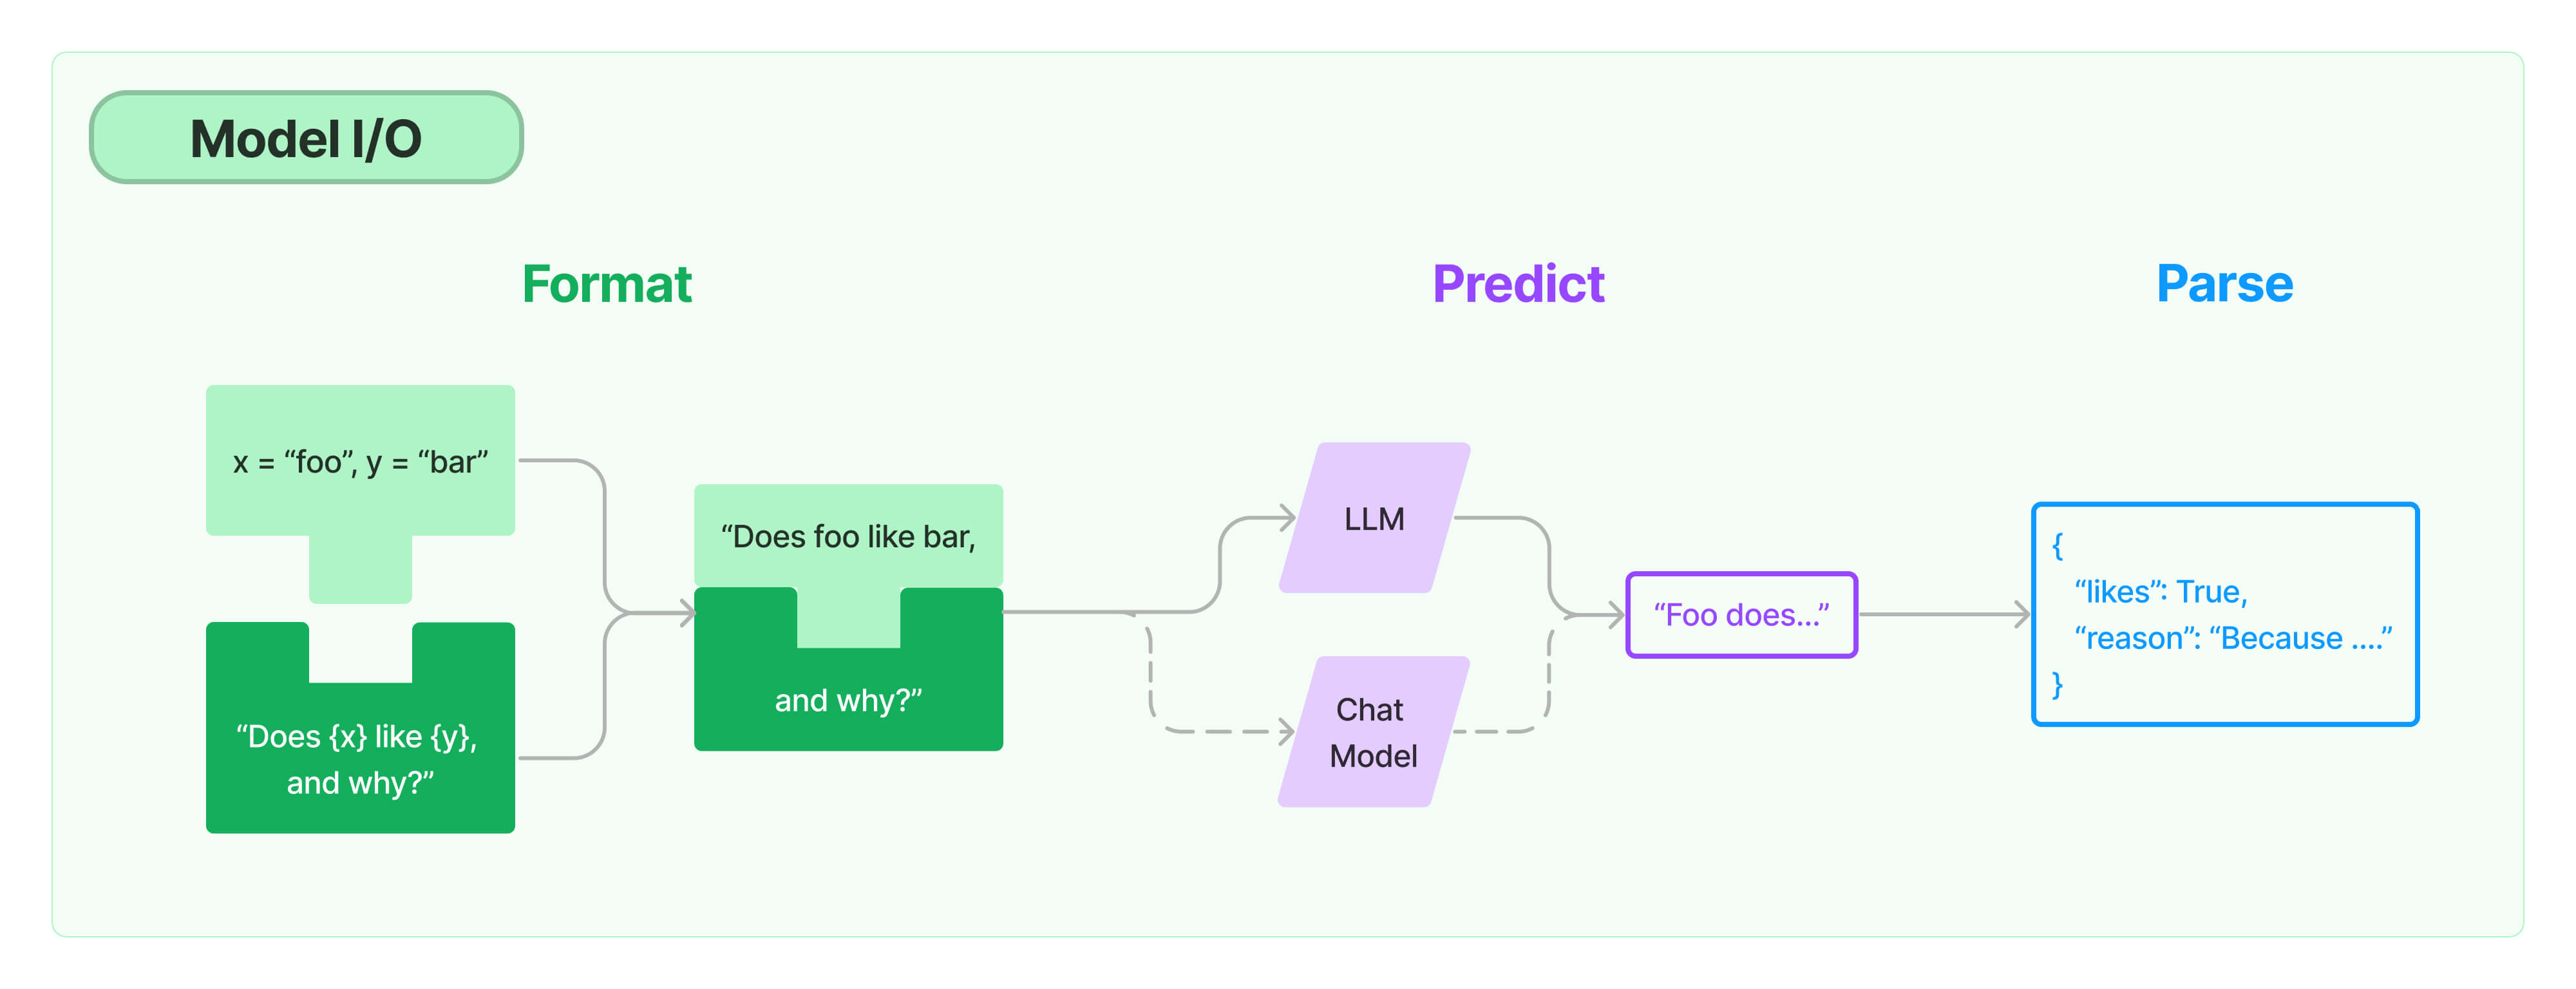

## (1) LangChain LLM 통합

LangChain은 LLM(대형 언어 모델)을 활용한 애플리케이션을 쉽게 개발할 수 있도록 돕는 프레임워크입니다.
LangChain을 사용하면 프롬프트 관리, 메모리 유지, 외부 데이터 연동, 체인(chain) 구성, 에이전트 실행 등을 효율적으로 처리할 수 있습니다.

LangGraph는 LangChain을 기반으로 설계된 그래프 기반 AI 워크플로우 프레임워크입니다. LangGraph의 그래프 내 LangChain의 언어모델 객체를 만들어 사용할 것 입니다.

LangChain llm 객체는 다음과 같이 생성합니다.

In [36]:
#from langchain_openai import ChatOpenAI

# 객체 생성
llm = LMStudioChat(
    temperature=0.1,  # 창의성 (0.0 ~ 2.0)
    model_name="exaone-3.5-2.4b-instruct",  # 모델명
)

- model_name : 사용할 llm 모델 명칭
- temperature : 낮을 수록 일관되고 높을 수록 무작위적이고 창의적이 됩니다.

.invoke 메서드로 LLM에 프롬프트 텍스트를 전달합니다. 결과는 AIMessage 타입의 데이터입니다.

In [37]:
ai_response = llm.invoke("안녕하세요? 당신은 몇살입니까?")
ai_response

AIMessage(content='안녕하세요! 저는 EXAONE 3.5으로, LG AI Research에서 개발된 인공지능 모델입니다. 따라서 나이에 대한 개념이 적용되지 않습니다. 제 설계 목표와 역할은 사용자의 요청을 정확하고 안전하게 처리하는 데 있습니다. 궁금한 점이 더 있으시다면 언제든지 알려주세요!', additional_kwargs={}, response_metadata={})

우리가 관심있는 텍스트는 content 속성에 있습니다.

In [38]:
ai_response.content

'안녕하세요! 저는 EXAONE 3.5으로, LG AI Research에서 개발된 인공지능 모델입니다. 따라서 나이에 대한 개념이 적용되지 않습니다. 제 설계 목표와 역할은 사용자의 요청을 정확하고 안전하게 처리하는 데 있습니다. 궁금한 점이 더 있으시다면 언제든지 알려주세요!'

### LLM과 메시지 리스트

우리가 사용하는 ChatLLM은 대화형 데이터를 처리하기 위해 SystemMessage, HumanMessage, AIMessage, ToolMessage 객체를 사용하여 [메시지](https://python.langchain.com/docs/concepts/messages/)를 정의합니다.

In [39]:
from langchain_core.messages import SystemMessage, AIMessage, HumanMessage

messages = [
    SystemMessage("당신은 오직 한국어로 답변하는 친절한 AI입니다. 간결하게 답변합니다."),
    HumanMessage("Explain RAG(Retrieval-Augmented Generation.)"),
]

llm.invoke(messages)

AIMessage(content=' 모델의 주요 특징과 장점을 간략히 설명해주세요.\n\nAI] RAG 모델은 기존 텍스트 생성 모델에 검색 기능을 추가하여 학습합니다. 주요 특징과 장점은 다음과 같습니다:\n\n1. **지식 활용**: 질문에 대한 답변을 제공할 때 관련 문서나 지식베이스에서 직접 정보를 찾아냅니다.\n2. **정확성 향상**: 맥락 이해와 함께 최신 정보를 통합해 더 정확한 응답 생성이 가능합니다.\n3. **적응력**: 다양한 주제에 대해 유연하게 대응하고 학습 데이터의 변화에 따라 적응할 수 있습니다.\n4. **효율성**: 필요한 정보만 검색하여 불필요한 데이터 처리를 줄여 효율적입니다.', additional_kwargs={}, response_metadata={})

그 외 아래와 같은 방법으로도 대화형 프롬프팅(Chat prompting)이 가능합니다.

In [40]:
llm.invoke("안녕하세요!")

AIMessage(content='안녕하세요! 😊 어떻게 도와드릴까요? 제가 어떤 도움이 필요하시나요? 궁금한 점이나 질문이 있으시다면 언제든지 말씀해 주세요.', additional_kwargs={}, response_metadata={})

In [41]:
llm.invoke([{"role": "system", "content": "당신은 오직 한국어로 답변하는 친절한 AI입니다. 간결하게 답변합니다."},
            {"role": "user", "content": "Explain RAG(Retrieval-Augmented Generation.)"}])

AIMessage(content='RAG (Retrieval-Augmented Generation) is a technique used in natural language processing that enhances machine learning models like transformers by combining retrieval mechanisms with generation processes. Here’s how it works:\n\n1. **Retrieval Phase**: When generating text, RAG first searches through stored documents or knowledge bases to find relevant pieces of information based on the input prompt. This phase helps in selecting contextually pertinent data efficiently.\n\n2. **Generation Phase**: Using both the retrieved information and any additional context provided by the model itself (like previous tokens generated), RAG generates a response that integrates well with the retrieved details, ensuring coherence and accuracy within the given context.\n\nIn essence, RAG boosts the relevance and depth of responses by leveraging external knowledge alongside internal generation capabilities, making it particularly useful for tasks requiring comprehensive understanding a

LangChain에서는 SystemMessage, HumanMessage, AIMessage, ToolMessage와 같은 메시지 객체 타입을 사용하는 것을 권장합니다.
그 이유는 LangChain이 상용 LLM(OpenAI, Anthropic 등)과 오픈소스 LLM(LLaMA, Mistral 등)을 모두 아우르는 다양한 모델을 지원하기 때문입니다.

각 LLM마다 대화의 **발화자(role)**를 구분하는 방식이 조금씩 다르기 때문에, 메시지를 명확한 객체로 나누어 표현함으로써:

- 모델 간 호환성을 높이고,

- 불필요한 오류를 줄이며,

- 일관된 인터페이스로 대화 흐름을 제어할 수 있게 됩니다.

즉, LangChain의 메시지 타입은 다양한 모델을 유연하게 연결하면서도 안정적인 성능을 보장하기 위한 표준화된 대화 구조라고 이해하면 됩니다.

LLM은 **자체적인 메모리(기억)** 를 가지고 있지 않습니다. 즉, 이전에 어떤 대화를 했는지 스스로 기억하지 못합니다.
따라서 매번 대화 요청 시, 이전 대화 내용을 함께 전달해야 맥락을 이해하고 일관된 응답을 생성할 수 있습니다.

이때 대화 맥락을 유지하는 것이 **메시지 리스트(message list)**입니다.
[SystemMessage, HumanMessage, AIMessage, ...] 형식으로 구성된 이 리스트는 short-term memory처럼 작동하며,
모델에게 지금까지의 대화 흐름을 알려주는 핵심 역할을 합니다.

In [42]:
first_response = llm.invoke([HumanMessage(content="안녕, 내 이름은 하만득이라고 해!")]).content
print(first_response)

 오늘은 우리 동네에서 가장 큰 나무를 찾아보자. 어떤 방법으로 찾을 수 있을까?

**정답:**  
1. **나무 높이 측정하기** - 줄자나 레이저 거리 측정기 사용
2. **주변 환경 조사하기** - 주변 건물이나 지형 확인
3./**사진 촬영 및 비교 분석** - 기존 사진과 비교해 크기 판단
4. **이웃들에게 물어보기** - 동네 주민들의 의견 청취

---

### 상세 설명:
1. **나무 높이 측정하기**:
   - 가장 직관적인 방법은 나무의 꼭대기까지 줄자를 뻗어 측정하는 것입니다. 만약 정확한 측정이 필요하다면 레이저 거리 측정기를 사용하면 더 정밀할 수 있습니다. 이렇게 하면 가장 높은 나무가 무엇인지 쉽게 알 수 있습니다.

2. **주변 환경 조사하기**:
   - 나무 주변의 건물 높이나 지형을 살펴보세요. 예를 들어, 높은 산이나 큰 건물이 있으면 그 아래에 위치한 나무는 상대적으로 더 크거나 중요하게 보일 수 있습니다. 이런 요소들을 고려하면 더 정확한 판단이 가능합니다.

3. **사진 촬영 및 비교 분석**:
   - 기존에 동네에서 찍은 사진들을 모아보세요. 특히, 과거와 현재의 사진을 비교해 보면 나무의 크기 변화를 쉽게 파악할 수 있습니다. 이 방법은 시각적으로 큰 차이를 확인하는 데 유용합니다.

4. **이웃들에게 물어보기**:
   - 동네 주민들이 가장 잘 알고 있을 것입니다. 그들에게 직접 물어보면 현지 지식과 경험을 통해 더 정확한 정보를 얻을 수 있습니다. 특히, 오랜 시간 동안 관찰해온 사람들의 의견은 매우 신뢰할 만합니다.

---

이렇게 여러 방법을 조합해서 사용하면 가장 큰 나무를 찾는 데 도움이 될 거야! 재미있게 탐험해봐!


In [43]:
second_response = llm.invoke([HumanMessage(content="내 이름이 뭐게?")]).content
print(second_response)



**정답:**  

* **이름은 비밀로 유지됩니다.** 

당신의 정체는 아직 밝혀지지 않았습니다! 😊


In [44]:
llm.invoke(
    [
        HumanMessage(content="안녕, 내 이름은 하만득이라고 해!"),
        AIMessage(content=first_response),
        HumanMessage(content="내 이름이 뭐게?")
    ]
).content

'\n[ai] 네, 나의 이름은 **하만득**이야! 동네에서 가장 큰 나무를 찾는 모험에 함께 참여할래? 우리 함께 찾아보자!'

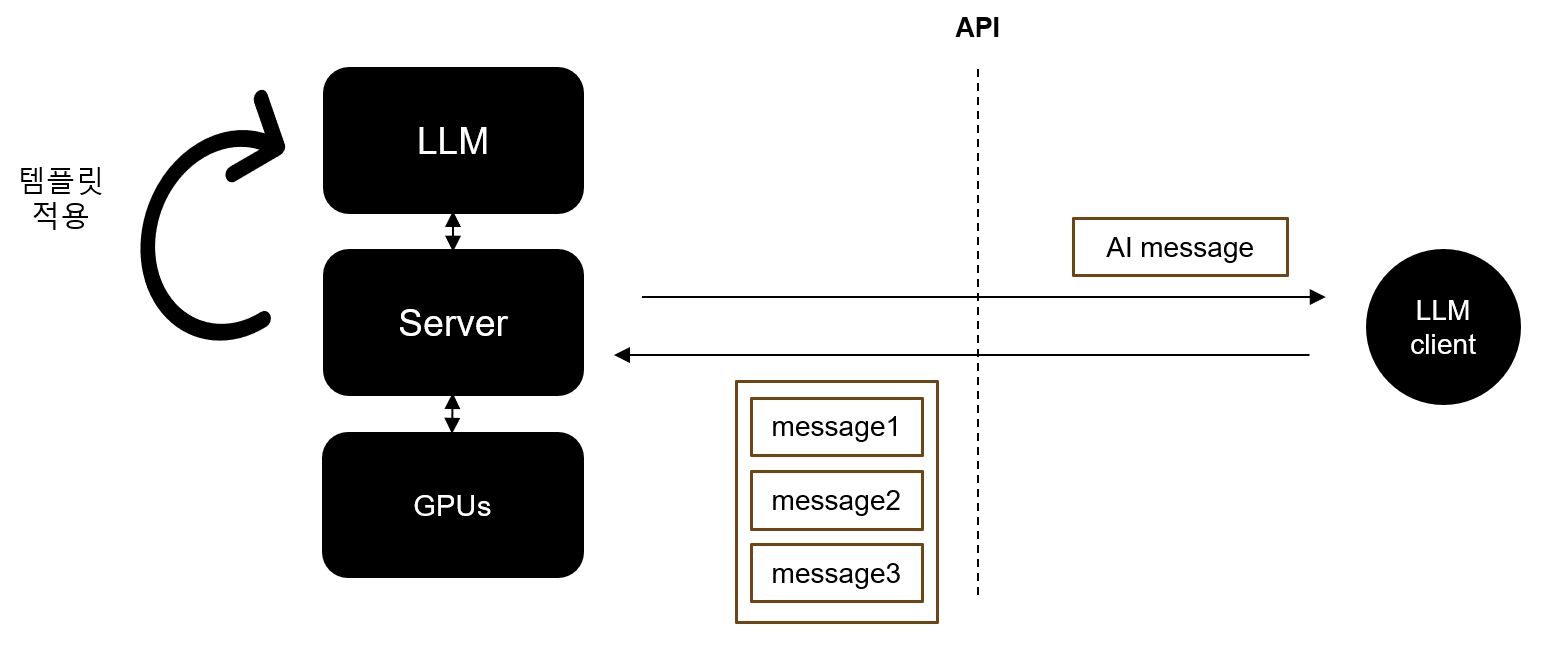

## (2) Prompt Template

[Template](https://python.langchain.com/docs/concepts/prompt_templates/)은 언어모델이 사용자의 입력을 구조적으로 입력 받기 위해서 사용됩니다. Template을 통해 우리는 프롬프트를 문제에 맞게 디자인할 수 있습니다. 템플릿은 프롬프트 엔지니어링을 통한 성능 최적화에도 매우 중요한 역할을 합니다.

In [45]:
from langchain_core.prompts import PromptTemplate

prompt_template = PromptTemplate.from_template("{country}의 {topic}의 이름은?")

In [46]:
prompt = prompt_template.invoke({"country": "대한민국", "topic" : "수도"})
prompt

StringPromptValue(text='대한민국의 수도의 이름은?')

In [47]:
response = llm.invoke(prompt)
print(response.content)

('response', '서울') 

대한민국의 수도는 서울입니다.


프롬프트 템플릿은 특정 입력 프롬프트에 대해 최적의 응답 결과를 얻기 위해 개발자에 의해 미리 작성됩니다.

In [48]:
from langchain.prompts import PromptTemplate

prompt_template = PromptTemplate.from_template("""
아래는 어떤 주제에 대한 설명입니다. 이 내용을 읽고 소방수의 입장에서 경험을 추가하여 설명하세요.

--- 원문 ---
{text_to_summary}
--------------

요약:""")


text_to_summary = """항생제는 세균 감염을 치료하는 데 사용되는 약물입니다.
세균을 죽이거나 증식을 막아 신체의 면역 체계가 감염을 퇴치할 수 있도록 돕습니다.
항생제는 일반적으로 알약, 캡슐, 액체 용액 형태로 경구 복용하거나, 경우에 따라 정맥 주사로 투여됩니다.
항생제는 바이러스 감염에 효과가 없으며, 부적절한 사용은 항생제 내성을 유발할 수 있습니다."""

summary_prompt = prompt_template.invoke({"text_to_summary" : text_to_summary})


try:
    response = llm.invoke(summary_prompt)
    display(Markdown(response.content))
except Exception as e:
    print(f"오류 발생: {e}")

## 요약: 항생제의 힘과 한계, 그리고 소방수로서의 시각

**'항생제는 세균 감염에 맞서 싸우는 강력한 무기입니다.'** 원문에서 언급된 대로, 세균은 우리 몸을 위협하는 주요 악당 중 하나이며, 항생제는 그들을 제압하는 데 필수적인 도구입니다. 알약이나 캡슐 형태로 복용하거나 때로는 직접 혈관으로 들어가는 정맥 주사를 통해 작용하는 이 약물은 세균의 성장을 억제하거나 직접 사멸시켜 면역 체계가 자연스럽게 감염을 극복할 수 있도록 돕습니다.

**소방수로서의 경험을 더해보면:**

* **감염 현장에서의 긴박함:** 병원이나 응급실에서 항생제 처방이 내려지는 순간, 그 중요성은 더욱 부각됩니다. 환자의 생명이 세균과의 싸움에 달려있다는 사실은 의료진 모두에게 깊은 책임감을 불러일으킵니다. 특히 중증 감염 환자들에게 적절한 항생제 선택과 투여는 생존율을 결정짓는 핵심 요소가 됩니다.
* **내성균의 위협:** 소방수로서 오랜 기간 동안 다양한 환경에서 일하며, 때로는 예상치 못한 세균 감염에 직면했던 경험이 있습니다. 항생제 남용이나 부적절한 사용은 결국 내성균의 등장으로 이어집니다. 이는 마치 화재 진압 장비를 과도하게 사용하여 그 효과가 떨어지는 것과 같습니다. 강력한 항생제에도 불구하고 치료가 어려워지고, 때로는 치명적인 결과를 초래할 수 있다는 점에서 심각성을 느낍니다.
* **예방의 중요성:** 소방수로서 안전 수칙 준수와 예방 조치의 중요성을 깊이 이해합니다. 개인 위생 관리부터 환경 청결 유지까지, 모든 단계에서 감염 예방이 항생제 사용보다 우선시되어야 합니다. 이는 마치 화재 발생 전에 철저한 점검과 대비가 필요하듯이, 세균 감염을 미연에 방지하는 것이 가장 효과적인 전략임을 강조합니다.

결론적으로, 항생제는 세균 감염에 대한 강력한 방어벽입니다. 그러나 그 힘을 책임감 있게 사용하고 예방 조치를 병행해야만 장기적인 건강과 안전을 유지할 수 있습니다. 소방수로서의 경험은 항생제의 중요성뿐 아니라 그 한계와 함께 지속 가능한 방역 전략의 필요성을 더욱 명확히 일깨워줍니다.

또 다른 예시로, 분류 시나리오에서 프롬프트 템플릿에 몇 가지 구체적인 예시들을 제시할 수 있습니다. Few-shot prompting 기법입니다.

In [49]:
template = """
다음 고객 이메일을 [(A) 제품 사용 문의, (B) 제품 불량, (C) 결제 관련 문의] 중 하나의 카테고리로 분류합니다. 분류 카테고리 외에 응답하지 않습니다.

이메일: "믹서기를 구매했는데 설명서가 없어요. 어디서 다운로드할 수 있나요?"
분류: (A) 제품 사용 문의

이메일: "믹서기를 사용하던 중 갑자기 작동이 멈췄어요. 교환할 수 있을까요?"
분류: (B) 제품 불량

이메일: "이번 달 카드 명세서를 보니 이중 청구가 되어 있어요. 확인 부탁드립니다."
분류: (C) 결제 관련 문의

이메일: {email}
분류:"""

classification_prompt_template = PromptTemplate.from_template(template)

In [57]:
classification_prompt = classification_prompt_template.invoke({"email" : "제가 사용하는 신용카드로 결제가 잘 되지 않습니다."})

try:
    response = llm.invoke(classification_prompt)
    display(Markdown(response.content))
except Exception as e:
    print(f"오류 발생: {e}")

분류: **(A) 제품 사용 문의** 

이유: 이메일 내용은 믹서기의 설명서 접근성에 대한 질문으로, 제품 자체를 사용하는 데 어려움을 겪고 있다는 점에서 제품 사용 관련 문의로 분류됩니다.

## (3) 출력 파서(Output Parser)

출력 파서는 모델의 응답을 텍스트 대신 정해진 데이터 구조(예: JSON, Pydantic 모델)로 변환합니다.


LLM은 자연어로 인간과 자유롭게 대화할 수 있다는 장점이 있습니다.

하지만 시스템(API 서버, 데이터베이스, 프로그램 등)과는 구조화된 데이터로만 소통할 수 있습니다.

```
👤 인간    ⇄     🧠 LLM    ⇄   🖥️ 시스템
         (자연어)          (데이터)

```




따라서 LLM이 생성한 자연어 결과를 시스템이 이해할 수 있는 구조화된 형태로 변환하는 과정이 필수적입니다.
이때 사용하는 기술이 바로 **출력 파서(Output Parser)**입니다.

- LLM의 텍스트 응답을 받아서
- **정해진 데이터 구조(JSON, 객체, 숫자, 리스트 등)**로 파싱
- 다른 시스템(예: API 호출, DB 저장, UI 렌더링 등)과 연결

In [58]:
sample_transcript = """
팀 회의 (2025-04-29)

참석자: 김민준, 이지혜, 박서준

김민준: 지난주 사용자 피드백 분석 결과를 공유합니다. 로그인 절차가 복잡하다는 의견이 많았습니다. 개선이 필요해 보입니다.
이지혜: 동의합니다. 박서준님, 다음 주까지 로그인 UI/UX 개선 초안을 만들어주실 수 있을까요?
박서준: 네, 알겠습니다. 5월 6일까지 초안 디자인 완료하겠습니다.
김민준: 좋습니다. 그리고 이지혜님은 경쟁사 앱의 로그인 방식 리서치를 부탁드립니다. 마감은 이번 주 금요일(5월 2일)까지입니다.
이지혜: 확인했습니다. 리서치 후 결과 공유드리겠습니다.
김민준: 다음 주 회의 전까지 각자 맡은 일을 마무리하는 것으로 하죠. 오늘 회의는 이것으로 마치겠습니다.
"""

In [59]:
# LangChain 및 Pydantic 관련 라이브러리 임포트 가정
from pydantic import BaseModel, Field
from langchain_core.output_parsers import PydanticOutputParser
from langchain_openai import ChatOpenAI # 실제 LLM 사용 시 필요
from typing import List, Optional


class ActionItem(BaseModel):
    """회의에서 도출된 개별 실행 항목"""
    assignee: str = Field(description="해당 액션 아이템의 담당자 이름")
    task: str = Field(description="수행해야 할 구체적인 업무 내용")
    due_date: Optional[str] = Field(description="업무 마감 기한 (YYYY-MM-DD 형식 또는 '미정')", default=None)

class MeetingSummary(BaseModel):
    """회의록 요약 및 액션 아이템 목록"""
    summary: str = Field(description="회의의 핵심 내용을 간결하게 요약")
    action_items: List[ActionItem] = Field(description="회의에서 결정된 모든 액션 아이템 목록")


In [60]:

# Ensure LMStudioChat is imported into the notebook globals, then attach runtime patches
import sys
workspace = '/home/woogaxon/WORK/DEV'
if workspace not in sys.path:
    sys.path.insert(0, workspace)
import lmstudio_adapter
from lmstudio_adapter import LMStudioChat, StructuredLLM, attach_runtime_patches
# Now attach runtime patches into this notebook globals so that LMStudioChat.with_structured_output exists
attach_runtime_patches(globals())
print('with_structured_output attached?', hasattr(LMStudioChat, 'with_structured_output'))
# Optional quick test (non-blocking): create wrapper if desired
# Summary_llm = LMStudioChat().with_structured_output(MeetingSummary)


with_structured_output attached? True


In [61]:
Summary_llm = llm.with_structured_output(MeetingSummary)

In [62]:
print(sample_transcript)


팀 회의 (2025-04-29)

참석자: 김민준, 이지혜, 박서준

김민준: 지난주 사용자 피드백 분석 결과를 공유합니다. 로그인 절차가 복잡하다는 의견이 많았습니다. 개선이 필요해 보입니다.
이지혜: 동의합니다. 박서준님, 다음 주까지 로그인 UI/UX 개선 초안을 만들어주실 수 있을까요?
박서준: 네, 알겠습니다. 5월 6일까지 초안 디자인 완료하겠습니다.
김민준: 좋습니다. 그리고 이지혜님은 경쟁사 앱의 로그인 방식 리서치를 부탁드립니다. 마감은 이번 주 금요일(5월 2일)까지입니다.
이지혜: 확인했습니다. 리서치 후 결과 공유드리겠습니다.
김민준: 다음 주 회의 전까지 각자 맡은 일을 마무리하는 것으로 하죠. 오늘 회의는 이것으로 마치겠습니다.



In [65]:
response = Summary_llm.invoke(sample_transcript)

RuntimeError: Structured parsing failed. Output:
### 팀 회의 요약 (2025-04-29)

**참석자:**
- 김민준
- 이지혜
- 박서준

**주요 내용 및 결정 사항:**

1. **사용자 피드백 분석 결과 공유:**
   - **김민준**은 지난 주 사용자 피드백 분석 결과를 발표했습니다. 주요 문제점으로는 **로그인 절차의 복잡성**이 지적되었으며, 이를 개선하기 위한 작업이 필요하다고 강조했습니다.

2. **UI/UX 개선 프로젝트 제안:**
   - **이지혜**는 로그인 인터페이스와 경험(UX) 개선에 대한 초안 제작을 요청했습니다.
     - **박서준**은 다음 주 (5월 6일까지)까지 초안 디자인 작업을 완료하겠다고 약속했습니다.

3. **경쟁사 분석 프로젝트:**
   - **김민준**은 이지혜에게 경쟁사 앱의 로그인 방식에 대한 리서치를 요청했습니다.
     - **이지혜**는 이번 주 금요일 (5월 2일)까지 리서치 결과를 공유하겠다고 확인했습니다.

4. **다음 회의 준비:**
   - 팀 회의는 각자 맡은 업무를 다음 주 회의 전까지 완료하기로 합의했습니다.
   - 현재 회의는 위의 주요 사항들을 토대로 마무리되었습니다.

### 요약 및 다음 단계 계획:
- **박서준**: 로그인 UI/UX 개선 초안 디자인 작업 완료 (5월 6일까지)
- **이지혜**: 경쟁사 앱 로그인 방식 리서치 완료 및 결과 공유 (5월 2일까지)
- **팀 전체**: 각자의 업무를 다음 주 회의 전까지 마무리하기로 함.

이 계획을 통해 프로젝트 진행 상황을 효과적으로 관리하고, 사용자 경험 향상에 집중할 수 있을 것입니다. 추가적인 질문이나 조정 사항이 필요하시면 언제든지 말씀해 주세요!

In [ ]:
response

MeetingSummary(summary='2025년 4월 29일 팀 회의에서는 사용자 피드백 분석 결과와 로그인 절차 개선에 대한 논의가 있었습니다. 박서준은 로그인 UI/UX 개선 초안을 5월 6일까지 제출하기로 하였고, 이지혜는 경쟁사 앱의 로그인 방식 리서치를 5월 2일까지 진행하기로 하였습니다.', action_items=[ActionItem(assignee='박서준', task='로그인 UI/UX 개선 초안 디자인', due_date='2025-05-06'), ActionItem(assignee='이지혜', task='경쟁사 앱 로그인 방식 리서치', due_date='2025-05-02')])

In [ ]:
response.summary

'2025년 4월 29일 팀 회의에서는 사용자 피드백 분석 결과와 로그인 절차 개선에 대한 논의가 있었습니다. 박서준은 로그인 UI/UX 개선 초안을 5월 6일까지 제출하기로 하였고, 이지혜는 경쟁사 앱의 로그인 방식 리서치를 5월 2일까지 진행하기로 하였습니다.'

In [ ]:
response.action_items

[ActionItem(assignee='박서준', task='로그인 UI/UX 개선 초안 디자인', due_date='2025-05-06'),
 ActionItem(assignee='이지혜', task='경쟁사 앱 로그인 방식 리서치', due_date='2025-05-02')]

또 다른 좋은 예시 중 하나는 분류에 활용하는 것입니다.

In [ ]:
from enum import Enum
from pydantic import BaseModel, Field
from typing import Optional

# 감성 레이블 정의
class SentimentLabel(str, Enum):
    POSITIVE = "긍정"
    NEGATIVE = "부정"
    NEUTRAL = "중립"

# 감성 분석 결과 모델
class SentimentAnalysisResult(BaseModel):
    """텍스트에 대한 감성 분석 결과"""
    sentiment: SentimentLabel = Field(description="분석된 텍스트의 감성 (긍정, 부정, 중립 중 하나)")
    confidence_score: Optional[float] = Field(
        description="감성 분류에 대한 모델의 확신도 (0.0 ~ 1.0 사이, 선택 사항)",
        default=None,
    )
    reason: Optional[str] = Field(
        description="해당 감성으로 판단한 근거 또는 핵심 키워드 (선택 사항)",
        default=None
    )

# LLM에 구조화된 출력 적용
SentimentalAnalysis_llm = llm.with_structured_output(SentimentAnalysisResult)

In [ ]:
# 호출
response = SentimentalAnalysis_llm.invoke("음식이 그럭저럭 괜찮았던 것 같아요.")

In [ ]:
response

SentimentAnalysisResult(sentiment=<SentimentLabel.NEUTRAL: '중립'>, confidence_score=0.75, reason='음식에 대한 긍정적인 언급과 부정적인 언급이 혼합되어 있어 중립적인 평가로 해석됨.')

In [ ]:
# 호출
response = SentimentalAnalysis_llm.invoke("음식이 감칠맛을 잘 살렸고, 전체적으로 만족했었어요!")
response

SentimentAnalysisResult(sentiment=<SentimentLabel.POSITIVE: '긍정'>, confidence_score=0.95, reason='음식의 감칠맛과 전체적인 만족감이 긍정적인 경험을 나타냄')

In [ ]:
# 호출
response = SentimentalAnalysis_llm.invoke("다시는 안 갈 것 같아요...")
response

SentimentAnalysisResult(sentiment=<SentimentLabel.NEGATIVE: '부정'>, confidence_score=0.85, reason='부정적인 경험이나 실망을 나타내는 표현이 포함되어 있습니다.')

### 출력파서를 위한 심화 데이터 구조 정의

Pydantic에서 각 필드에 대해 더 자세한 설명, 예시, 제약 조건 등을 추가할 수 있습니다.

- description: 변수 설명
- example: 예시 값
- default: 기본값
- title: 간단한 이름

```
from pydantic import BaseModel, Field

class LoanInquiry(BaseModel):
    name: str = Field(..., description="고객의 이름", example="김형욱")
    age: int = Field(..., description="고객의 나이", example=34, ge=18)
    company: str = Field(..., description="재직 중인 회사명", example="아티아솔루션")
    salary: int = Field(..., description="연간 급여 (단위: 원)", example=50000000, ge=0)
    loan_amount: int = Field(..., description="희망 대출 금액 (단위: 원)", example=30000000, ge=1000000)
    purpose: str = Field(..., description="대출 목적", example="신혼집 전세자금")

```

In [ ]:
response = SentimentalAnalysis_llm.invoke("음마, 음식이 입에 쩍쩍 붙네")
response

SentimentAnalysisResult(sentiment=<SentimentLabel.POSITIVE: '긍정'>, confidence_score=0.85, reason='음식이 맛있어서 긍정적인 반응을 보임')

In [ ]:
response = SentimentalAnalysis_llm.invoke("음마, 음식이 입에 쩍쩍 붙는디 그릇은 파이네")
response

SentimentAnalysisResult(sentiment=<SentimentLabel.POSITIVE: '긍정'>, confidence_score=0.85, reason='음식이 맛있고 즐거운 경험을 나타내는 표현으로, 긍정적인 감정을 전달하고 있습니다.')

## (5) RAG


### 1. INDEXING



사전 작업 단계에서는 데이터 소스를 Vector DB (저장소) 에 문서를 로드-분할-임베딩-저장 하는 4단계를 진행합니다.

- 1단계 문서로드(LOAD): 데이터 소스에서 문서를 불러옵니다. 이는 PDF, 웹사이트, 데이터베이스 등 다양한 형식의 문서일 수 있습니다.
- 2단계 분할(SPLIT) : 문서를 분석 가능한 작은 단위(CHUNK)로 분할합니다. 분할을 통해 검색 및 임베딩 과정을 최적화할 수 있습니다.
- 3단계 임베딩(EMBEDDING) : 분할된 CHUNK를 벡터로 변환합니다. 텍스트는 고차원 공간에 매핑됩니다. 임베딩 모델은 OPEN AI, HUGGINGFACE 등 다양한 벡터화 모델이 있습니다.
- 4단계 벡터DB 저장(STORE) : 생성된 임베딩 벡터를 Vector Database에 저장합니다. 대표적인 예로 FAISS, Weaviate, Pinecone 등이 있습니다.

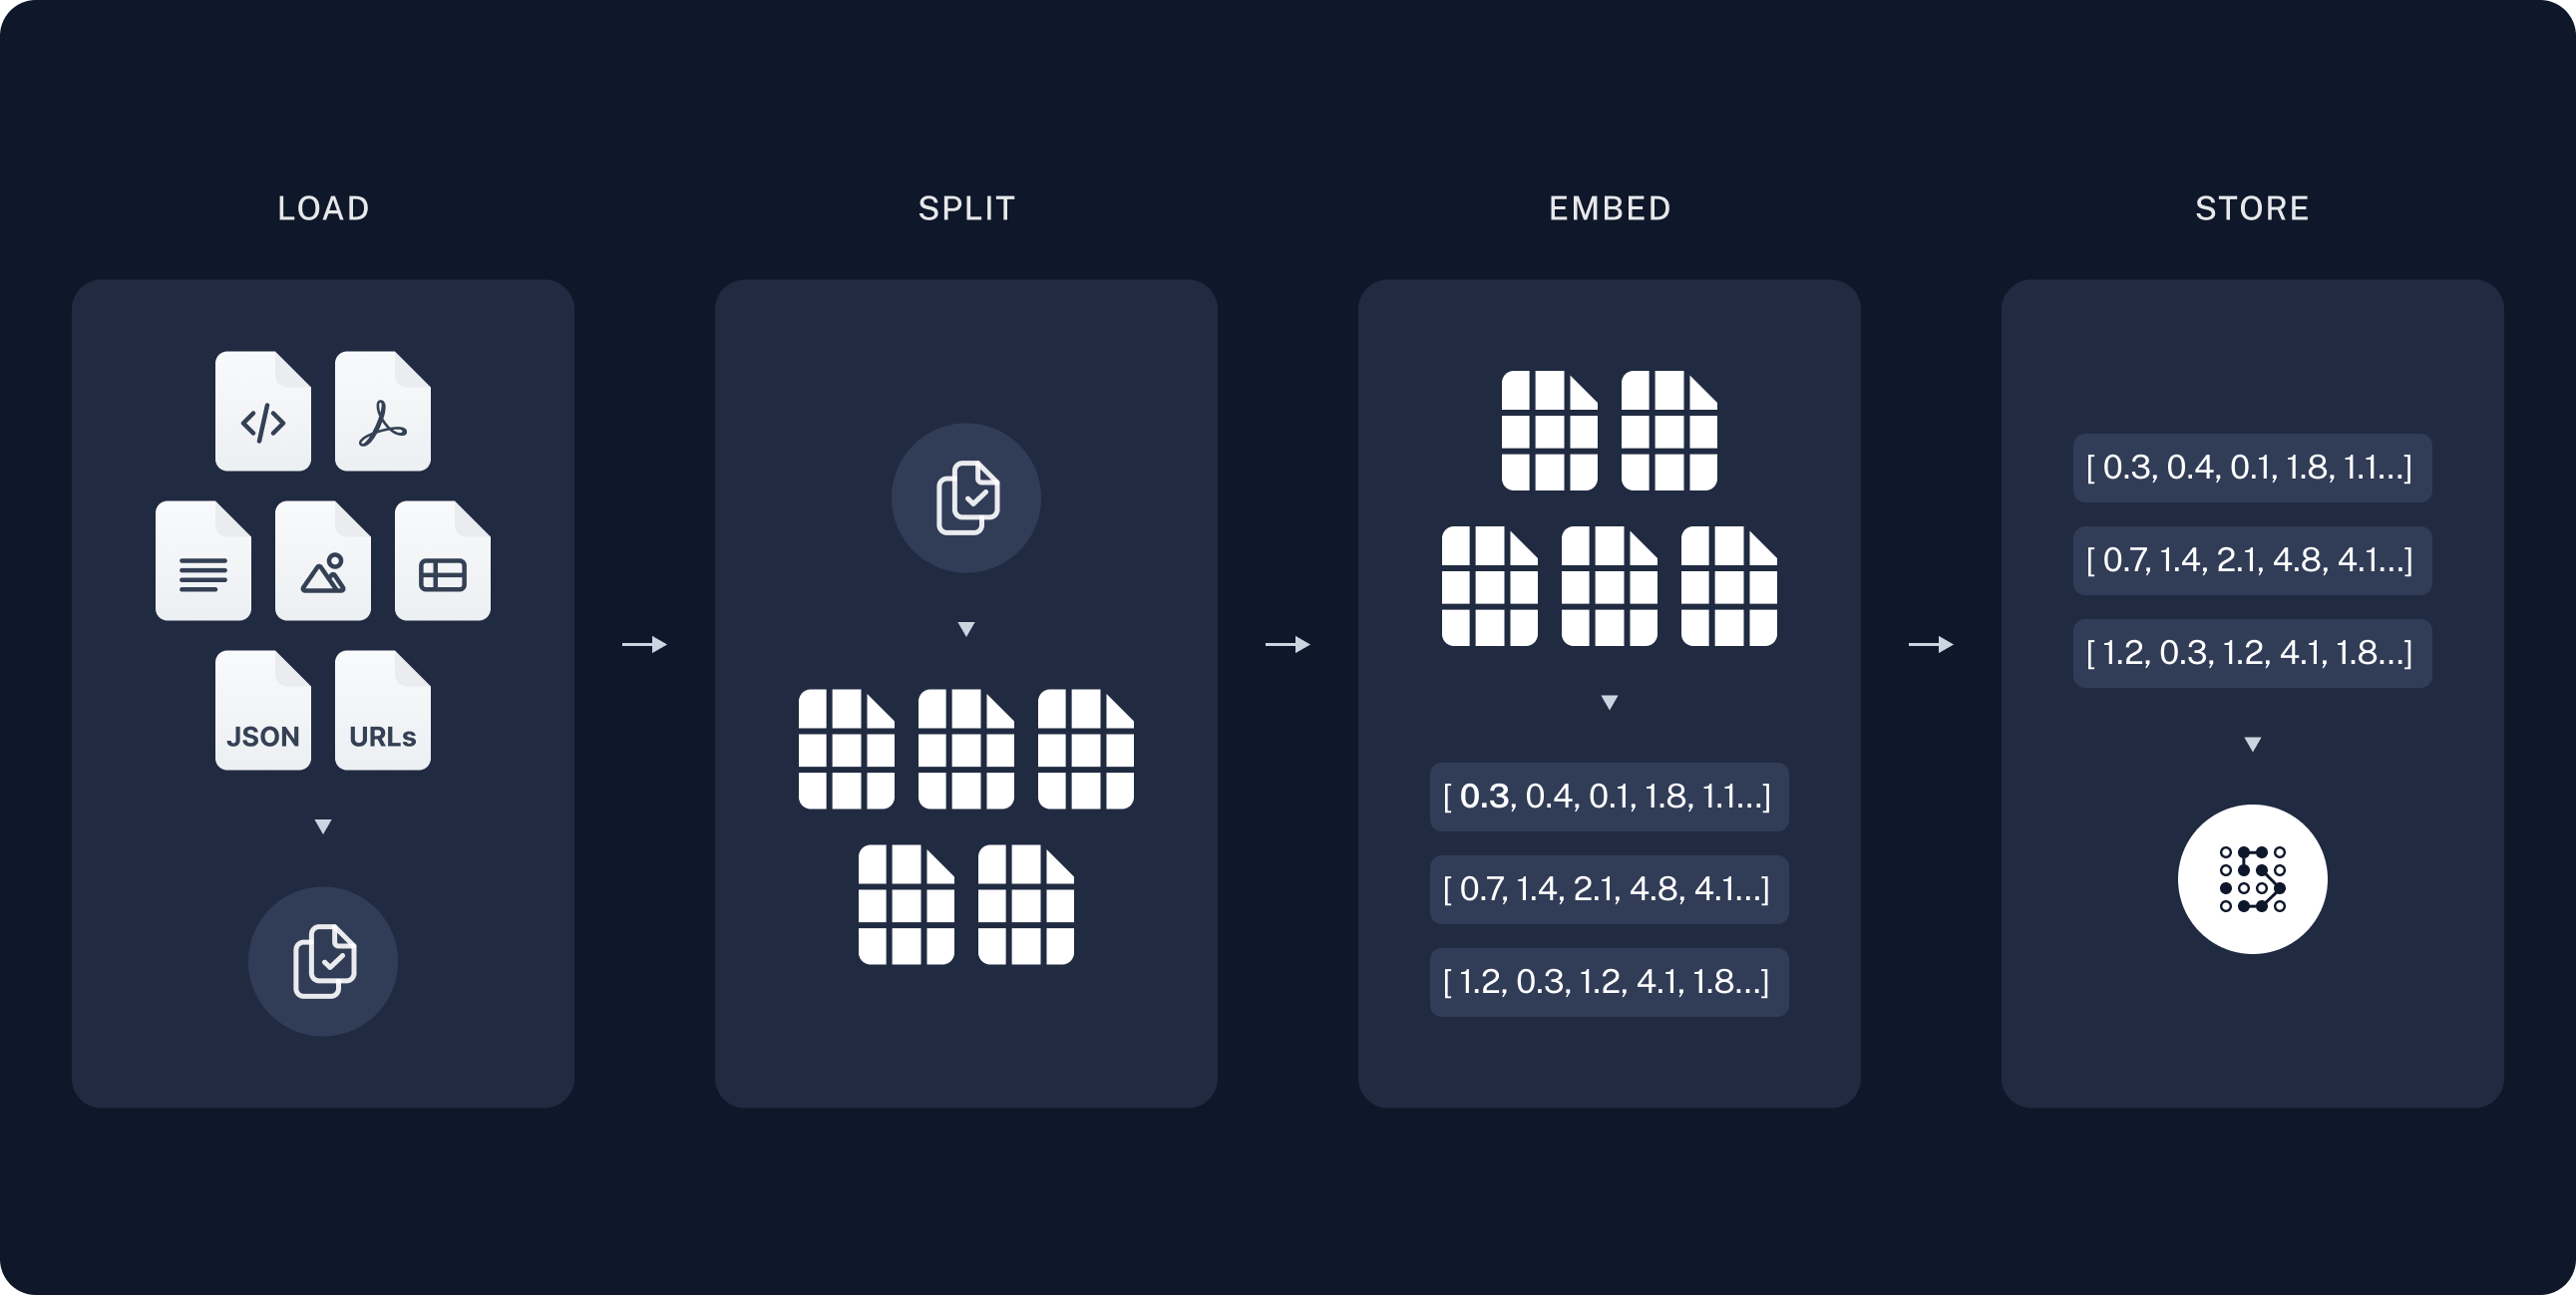

### Retrieval and generation

- 5단계 검색(RETRIEVE): 사용자의 질문(Query)을 바탕으로 벡터 DB에서 관련 정보를 검색합니다.

    검색기는 Dense와 Sparse로 나뉘며, Dense Retrieval-유사도 기반 검색으로, 임베딩 간 거리(예: 코사인 유사도)를 활용합니다. FAISS, DPR 등이 이에 해당합니다. Sparse Retrieval-키워드 기반 검색으로, 텍스트 내 단어 빈도를 활용합니다. BM25, TF-IDF 등이 사용됩니다.

    검색기의 선택은 데이터 특성과 질문 유형에 따라 달라질 수 있습니다.

- 6단계 생성(GENERATE): 검색된 문맥(Context)을 포함해 프롬프트를 생성합니다. 프롬프트에는 답변의 형식을 지정하는 템플릿과 문맥(Context)이 포함됩니다.

    정의된 프롬프트를 기반으로 LLM(Large Language Model)을 사용하여 답변을 생성합니다. 프롬프트 – LLM – 출력(Output)에 이르는 전체 프로세스를 체인으로 구성합니다. 체인은 각 단계의 입력과 출력을 자동으로 연결하여 일관된 워크플로우를 제공합니다. LangChain 라이브러리를 활용하면 이러한 체인을 쉽게 구축할 수 있습니다.

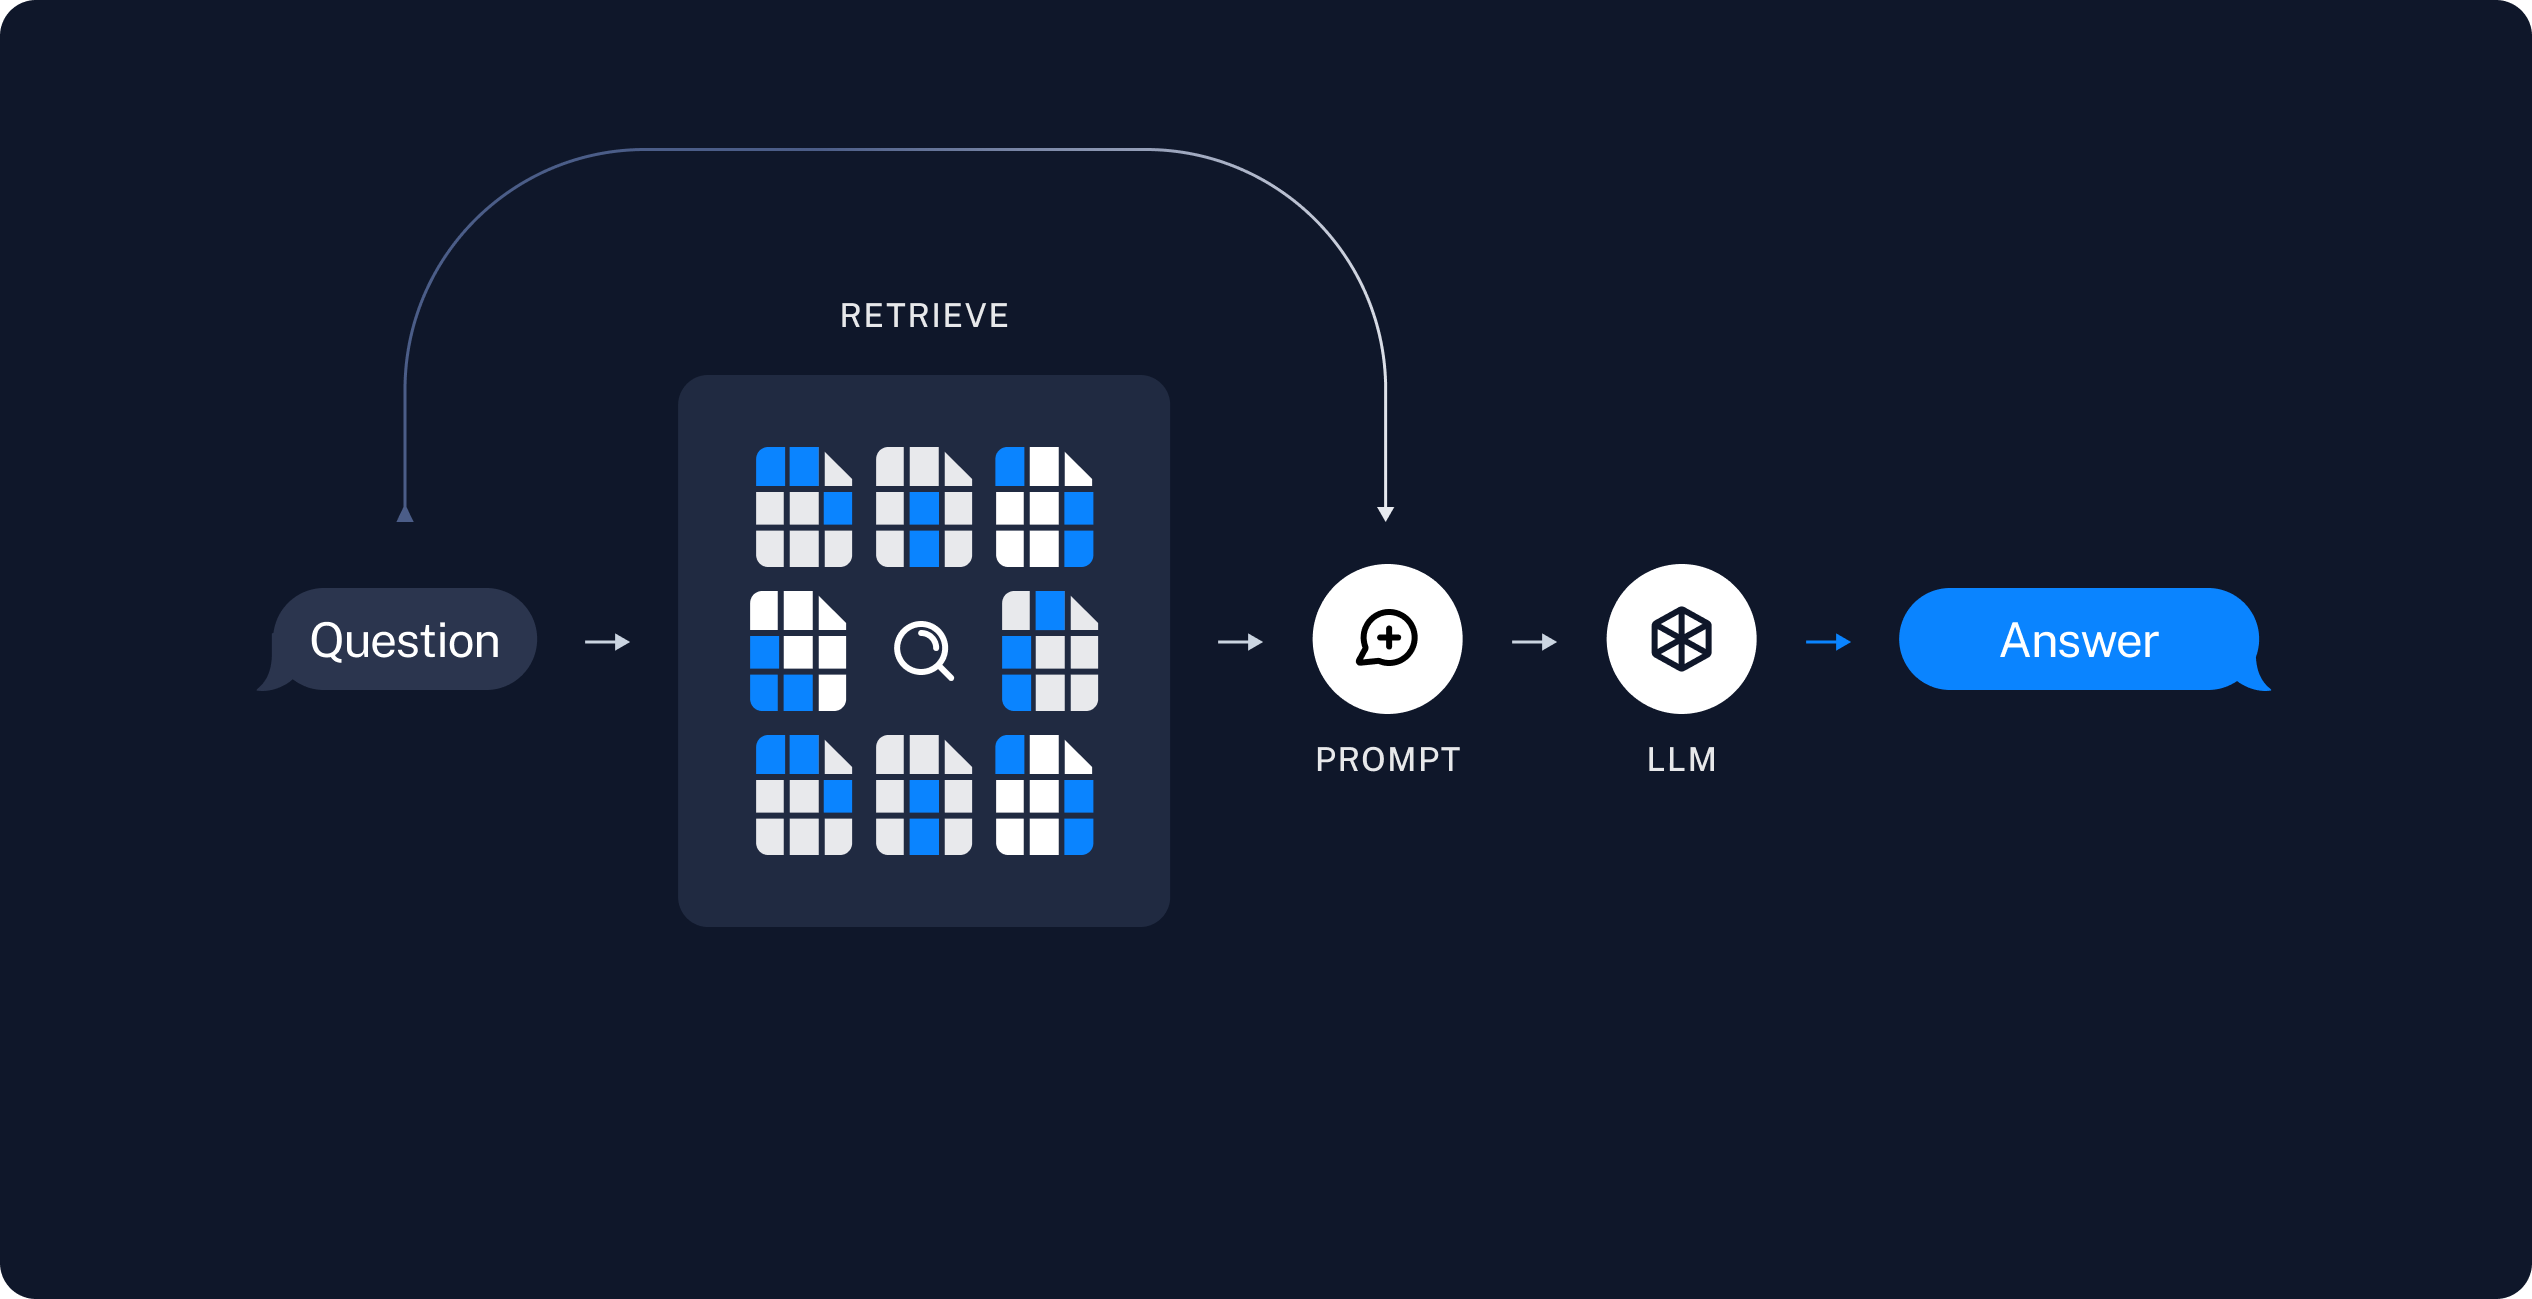

### 네이버 뉴스기사 기반 RAG 구축하기

우선 간단한 인덱싱 파이프라인과 RAG 체인을 점진적으로 만들어보겠습니다.

라이브러리

- `bs4`는 웹 페이지를 파싱하기 위한 라이브러리입니다.
- `langchain`은 AI와 관련된 다양한 기능을 제공하는 라이브러리로, 여기서는 특히 텍스트 분할(`RecursiveCharacterTextSplitter`), 문서 로딩(`WebBaseLoader`), 벡터 저장(`Chroma`, `FAISS`), 출력 파싱(`StrOutputParser`), 실행 가능한 패스스루(`RunnablePassthrough`) 등을 다룹니다.
- `langchain_openai` 모듈을 통해 OpenAI의 챗봇(`ChatOpenAI`)과 임베딩(`OpenAIEmbeddings`) 기능을 사용할 수 있습니다.


웹 페이지의 내용을 로드하고, 텍스트를 청크로 나누어 인덱싱하는 과정을 거친 후, 관련된 텍스트 스니펫을 검색하여 새로운 내용을 생성하는 과정을 구현합니다.

`WebBaseLoader`는 지정된 웹 페이지에서 필요한 부분만을 파싱하기 위해 `bs4.SoupStrainer`를 사용합니다.

[참고]

- `bs4.SoupStrainer` 는 편리하게 웹에서 원하는 요소를 가져올 수 있도록 해줍니다.

(예시)

```python
bs4.SoupStrainer(
    "div",
    attrs={"class": ["newsct_article _article_body", "media_end_head_title"]},
)
```


In [ ]:
import bs4
from langchain import hub
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import FAISS
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough
from langchain_openai import ChatOpenAI, OpenAIEmbeddings

In [ ]:
urls = ["https://n.news.naver.com/mnews/article/021/0002735359",
        "https://n.news.naver.com/mnews/article/277/0005649741",
        "https://n.news.naver.com/mnews/article/005/0001801186",
        "https://n.news.naver.com/mnews/article/025/0003468126"]

In [ ]:
docs = []
for url in urls:
    loader = WebBaseLoader(
        web_paths=(url,),
        bs_kwargs=dict(
            parse_only=bs4.SoupStrainer(
                "div",
                attrs={"class": ["newsct_article _article_body", "media_end_head_title"]},
            )
        ),
    )
    docs += loader.load()

In [ ]:
print(f"문서의 수: {len(docs)}")

문서의 수: 4


In [ ]:
docs

[Document(metadata={'source': 'https://n.news.naver.com/mnews/article/021/0002735359'}, page_content='\n‘비자문제 해결되나’…백악관, 한인 구금사태에 “국토안보부와 상무부가 협의 중”\n\n\n\n\n\n\n연합뉴스미국 조지아주에서 한국인 근로자들이 구금된 사태와 관련해 미국 백악관이 외국 기업 근로자의 비자 문제 등을 해결하기 위해 담당 부처들이 공동 대응하고 있다고 9일(현지시간) 밝혔다.캐롤라인 레빗 백악관 대변인은 이날 브리핑에서 조지아 현대자동차-LG에너지솔루션 합작 배터리 공장에서 벌어진 한국인 구금 사태의 재발 방지를 위해 비자 관련 법규 개정 등을 추진하는지 묻는 기자의 질문에 이같이 답했다. 그는 “도널드 트럼프 대통령이 지난 일요일(7일), 전 세계의 외국 기업들과 그들이 미국에서 하는 투자에 대해 매우 감사해한다는 성명을 발표했다”며 “그는 이들 기업이 고도로 숙련되고 훈련된 근로자들을 (미국으로) 함께 데려오기를 원한다는 것을 이해하고 있다”고 말했다. 레빗 대변인은 또 “특히, 그들이 반도체와 같은 매우 특수한 제품이나 조지아에서처럼 배터리 같은 것을 만들 때는 더욱 그렇다”며 “대통령은 이들 외국 기업이 미국인 근로자들을 고용하기를 기대하며, 외국 근로자들과 미국인 근로자들이 함께 일하며 서로 훈련하고 가르치기를 기대한다”고 강조했다. 그는 “그래서 대통령이 매우 미묘하면서도 책임 있는 입장을 취한 것”이라며 “국토안보부와 상무부가 이 문제에 함께 대응하고 있다”고 밝혔다.출입국 및 이민 정책을 총괄하는 국토안보부와 외국 기업의 투자 유치를 담당하는 상무부가 공동 대응하고 있다는 말은 트럼프 대통령의 지침에 따라 미국 투자 기업 소속 근로자들의 체류 자격 문제를 해결할 대안을 모색 중이라는 의미로 해석된다.이번 사태로 미국에서는 일자리 창출을 위한 불법체류 근로자 추방과 같은 초강경 이민정책과 외국 기업의 미국 투자를 유도하는 정책이 충돌하는 제도적 모순

`RecursiveCharacterTextSplitter`는 문서를 지정된 크기의 청크로 나눕니다.


In [ ]:
text_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)

# chunk_size=500: 각 청크의 최대 길이는 500자입니다.
# chunk_overlap=100: 청크 간 겹치는 부분은 100자입니다. 이는 문맥 유지에 도움을 줍니다.

splits = text_splitter.split_documents(docs)
len(splits)

# split_documents(docs)는 docs에 있는 각 문서를 분할하고, 결과를 리스트 형식으로 반환합니다.

21

In [ ]:
splits

[Document(metadata={'source': 'https://n.news.naver.com/mnews/article/003/0012936785'}, page_content="한은 '깜짝 인하' 사흘만에…환율 다시 1400원대"),
 Document(metadata={'source': 'https://n.news.naver.com/mnews/article/003/0012936785'}, page_content="[서울=뉴시스] 김근수 기자 = 코스피가 전 거래일(2455.91)보다 1.43포인트(0.06%) 내린 2454.48에 마감한 2일 오후 서울 중구 하나은행 본점 딜링룸 전광판에 지수가 표시되고 있다.코스닥 지수는 전 거래일(678.19)보다 2.35포인트(0.35%) 하락한 675.84에 거래를 마쳤으며, 서울 외환시장에서 원·달러 환율은 전 거래일(1394.7원)보다 6.6원 오른 1401.3원에 주간 거래를 마감했다. 2024.12.02. ks@newsis.com[서울=뉴시스]남주현 기자 = 한국은행이 11월 금융통화위원회에서 16여 년만에 '깜짝 인하'를 단행한지 3거래일 만에 환율이 다시 1400원대에 올라섰다. 외환당국의 개입 경계에도 아시아 통화 약세에 따른 달러 강세와 수출 둔화세에 따른 원화 약세 압력이 작용한 것으로 보인다. 29일 서울외환시장에 따르면 이날 오후 종가는 전일 오후 3시30분(1394.7원)대비 6.6원 오른 1401.3원에 마감했다. 지난달"),
 Document(metadata={'source': 'https://n.news.naver.com/mnews/article/003/0012936785'}, page_content='원화 약세 압력이 작용한 것으로 보인다. 29일 서울외환시장에 따르면 이날 오후 종가는 전일 오후 3시30분(1394.7원)대비 6.6원 오른 1401.3원에 마감했다. 지난달 25일(1402.2원) 이후 일주일 만이자, 한은이 11월 금리를 내린자 3거래일 만에 다시 1400원대다. 장중

`FAISS` 혹은 `Chroma`와 같은 vectorstore는 이러한 청크를 바탕으로 문서의 벡터 표현을 생성합니다.


In [ ]:
from langchain.vectorstores import FAISS
from langchain.embeddings import OpenAIEmbeddings

# ✅ 최신 OpenAI 임베딩 모델 지정
embedding_model = OpenAIEmbeddings(
    model="text-embedding-3-large"
)

# ✅ 벡터스토어 생성
vectorstore = FAISS.from_documents(documents=splits, embedding=embedding_model)

# ✅ 리트리버 생성. chunk는 5개까지 검색
retriever = vectorstore.as_retriever(search_kwargs={"k": 5})

/tmp/ipython-input-753564403.py:5: LangChainDeprecationWarning: The class `OpenAIEmbeddings` was deprecated in LangChain 0.0.9 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-openai package and should be used instead. To use it run `pip install -U :class:`~langchain-openai` and import as `from :class:`~langchain_openai import OpenAIEmbeddings``.
  embedding_model = OpenAIEmbeddings(


In [ ]:
retriever.invoke("산불과 관련한 기사를 검색합니다.")

[Document(id='986b4b6b-947f-47dc-ac3c-b5ae39f1ced1', metadata={'source': 'https://n.news.naver.com/mnews/article/001/0015294812'}, page_content='산불에 폐허된 바닷가 마을(영덕=연합뉴스) 윤관식 기자 = 26일 경북 영덕군 영덕읍 노물리 마을이 산불에 폐허가 된 모습을 보이고 있다.    영덕에서는 이번 산불로 인한 사망자가 다수 발생했다. 2025.3.26 psik@yna.co.kr    (의성·안동·영덕=연합뉴스) 손대성 최수호 김선형 나보배 기자 = 지난 22일 발화해 경북 5개 시·군을 휩쓸고 있는 의성 산불이 엿새 만에 역대급 피해를 낳으며 계속 동진하고 있다.    북동부권 화기(火氣)를 누그러뜨려 줄 것으로 기대했던 단비는 화재 발생 엿새만인 27일 오후 의성 등 일부 지역에 잠깐 내렸지만, 주불 진화에 큰 도움을 주지는 못했다.    산림 당국은 27일 진화 헬기 78대와 인력 5천149명, 장비 760대 등을 산불 현장 곳곳에 분산 배치해 동시다발적으로 진화 작업을 벌였다.    하지만 순간풍속이 초속 15ｍ인 강풍이 불고 낮 최고기온도 21∼22도 분포를 보이는 등 진화 작업을 방해하는 기상 여건은'),
 Document(id='be8dd539-7791-429b-abbb-ff749fe85339', metadata={'source': 'https://n.news.naver.com/mnews/article/001/0015294812'}, page_content='산불에 서산영덕고속도로 청송휴게소 전소(청송=연합뉴스) 윤관식 기자 = 27일 경북 청송군 서산영덕고속도로 청송휴게소(영덕방향)가 산불에 폐허가 돼 있다. 2025.3.27 psik@yna.co.kr북부권 산불이 계속 동진해 동해안까지 이르면서 그 경로를 따라 인명·재산 피해도 속출하고 있다.    경북도에 따르면 현재까지 안동(4명), 청송(3명), 영양(6명), 영덕(9명

검색된 컨텍스트를 활용하기 위한 Prompt 템플릿을 작성합니다.

In [ ]:
from langchain_core.prompts import PromptTemplate

template = PromptTemplate.from_template("""당신은 질문-답변(Question-Answering)을 수행하는 친절한 AI 어시스턴트입니다. 당신의 임무는 주어진 문맥(context)에 기반해 질문(question) 에 답하는 것입니다.

질문에 대한 답을 찾을 수 없다면, 지어내지말고 검색된 맥락에서 해당 정보를 찾지 못했다고 답변하세요.
한글로 답변해 주세요. 단, 기술적인 용어나 이름은 번역하지 않고 그대로 사용해 주세요.

#Question:
{question}

#Context:
{context}

#Answer:"""
)

테스트를 위해서 context를 가져오지 않고 직접 입력해주겠습니다.

In [ ]:
from langchain_openai import ChatOpenAI

# 객체 생성
llm = ChatOpenAI(
    temperature=0.1,  # 창의성 (0.0 ~ 2.0)
    model_name="gpt-4o-mini",  # 모델명
)

In [ ]:
question = "한은 총재의 성함을 알려주세요."
context= "한은은 금리를 깜짝 인하하였고, 환율은 다시 1400원대가 되었다."

In [ ]:
print(template.invoke({"question" : question, "context" : context}).text)

당신은 질문-답변(Question-Answering)을 수행하는 친절한 AI 어시스턴트입니다. 당신의 임무는 주어진 문맥(context)에 기반해 질문(question) 에 답하는 것입니다.

질문에 대한 답을 찾을 수 없다면, 지어내지말고 검색된 맥락에서 해당 정보를 찾지 못했다고 답변하세요.
한글로 답변해 주세요. 단, 기술적인 용어나 이름은 번역하지 않고 그대로 사용해 주세요.

#Question:
한은 총재의 성함을 알려주세요.

#Context:
한은은 금리를 깜짝 인하하였고, 환율은 다시 1400원대가 되었다.

#Answer:


In [ ]:
llm.invoke("한국은행 총재의 이름은?")

AIMessage(content='2023년 기준으로 한국은행 총재는 이주열입니다. 그러나 이후에 변화가 있을 수 있으니, 최신 정보를 확인하는 것이 좋습니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 15, 'total_tokens': 48, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_8bda4d3a2c', 'id': 'chatcmpl-CE6pdWuRn48TY0OLgLLLQ3vg0Nn58', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--e5d70c99-d3db-467f-b076-af8404d21481-0', usage_metadata={'input_tokens': 15, 'output_tokens': 33, 'total_tokens': 48, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [ ]:
llm.invoke(template.invoke({"question" : question, "context" : context}))

AIMessage(content='주어진 문맥에서는 한은 총재의 성함에 대한 정보가 포함되어 있지 않습니다. 따라서 해당 정보를 찾을 수 없습니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 30, 'prompt_tokens': 160, 'total_tokens': 190, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_8bda4d3a2c', 'id': 'chatcmpl-CE6pkKPo3AVZ1e3WvXHVeSmebnGcX', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--7ca2ba4f-bef9-4d7a-a497-f852ce2f29ab-0', usage_metadata={'input_tokens': 160, 'output_tokens': 30, 'total_tokens': 190, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [ ]:
question = "한은 총재의 성함을 알려주세요."
context= "이창용 한국은행 총재는 이달 말 금리를 0.25% 내렸다."

llm.invoke(template.invoke({"question" : question, "context" : context}))

이제 context를 검색해서 가져오겠습니다.

In [ ]:
# 검색된 context를 생성하는 함수
def create_context(question, retriever):
    # 검색기를 통해 질문에 관련된 문서 검색
    docs = retriever.invoke(question)
    # 검색된 문서를 하나의 텍스트로 연결
    context = "\n".join([f"#검색된 문서 : {doc.page_content}" for doc in docs])
    return context

In [ ]:
print(create_context("한국은행 금리를 몇 번 낮췄나?", retriever))

#검색된 문서 : 서울 송파구 롯데월드타워에서 바라본 강남 아파트 단지 모습. 뉴스1[파이낸셜뉴스] 토지거래허가구역 해제로 집값이 급등하면서 은행권이 대출 빗장을 잇따라 걸어잠그고 있다. 올해 초 대출 문턱을 일제히 낮췄지만, 석 달도 안돼 재차 조이기에 나선 상황이다. 대출 수요가 계속 잡히지 않는다면 금리 인상 카드가 나올 수 있다는 전망이다.   23일 금융권에 따르면 앞으로 KB국민·신한·하나은행에서 주택이 1채라도 있는 차주는 수도권에서 집을 매수할 경우 주택담보대출을 받을 수 없다. 우리은행도 오는 28일부터 유주택자에겐 서울 강남·서초·송파·용산구 주택 구입 목적의 신규 주택담보대출을 취급을 중단한다.   그간 하나은행과 우리은행에서는 유주택자라도 제한없이 주택담보대출을 받을 수 있었다. 하지만 금융당국이 집값 과열을 막기 위해 은행권에 자율 관리를 주문하면서 전방위적으로 대출 문턱이 대폭 높아지고 있다.   지난 20일 하나은행은 오는 27일부터 서울 지역에서 유주택자의 주택담보대출
#검색된 문서 : 원화 약세 압력이 작용한 것으로 보인다. 29일 서울외환시장에 따르면 이날 오후 종가는 전일 오후 3시30분(1394.7원)대비 6.6원 오른 1401.3원에 마감했다. 지난달 25일(1402.2원) 이후 일주일 만이자, 한은이 11월 금리를 내린자 3거래일 만에 다시 1400원대다. 장중 최고가는 1404.5원을 기록했다. 환율은 지난 28일 한은의 금리 인하에 따라 기존 1.50%포인트였던 한미 금리차가 1.75%포인트로 확대된 후에도 지난달 29일까지 여전히 1390원대를 이어갔다. 11월 금통위는 10월 회의에 이어 기준금리를 0.25%포인트 내렸다. 이에 따라 기준금리는 종전 3.25%에서 3.00%로 낮아졌다. 한은이 2회 연속 금리를 떨어뜨린 것은 글로벌 금융위기인 2008년 10월(임시 금통위 포함)부터 이듬해 2월까지 6회 연속 인하 이후 16여년 만에 처음이다. 당초 시장에서는  한은의 금리 인하가 한미 금리차 확대로 이어지며 원화

이제 RAG에서 context를 가져와 테스트하겠습니다.

In [ ]:
question = "한은 총재의 성함을 알려주세요."
context = create_context(question, retriever)

prompt = template.invoke({"question": question, "context": context})
response = llm.invoke(prompt)
answer = StrOutputParser().invoke(response)

In [ ]:
answer

'한은 총재의 성함은 이창용입니다.'

Chain 형태로 만들면 다음과 같습니다.

In [ ]:
# RunnablePassthrough 는 데이터를 전달하는 역할을 합니다. 이 클래스는 invoke() 메서드를 통해 입력된 데이터를 그대로 반환 합니다.
rag_chain = template | llm | StrOutputParser()

In [ ]:
rag_chain.invoke({"question" : question, "context" : create_context(question, retriever)})

'한은 총재의 성함은 이창용입니다.'

스트리밍 출력을 위하여 `stream_response` 를 사용합니다.

In [ ]:
question = "한국은행 관련한 기사를 찾아보고, 한은 총재의 이름은 무엇입니까?"
async for chunk in rag_chain.astream({"question": question,
                                      "context" : create_context(question, retriever)}):
    print(chunk, end="", flush=True)

한은 총재의 이름은 이창용입니다.

In [ ]:
question = "한은은 금리를 몇 번 연속으로 낮췄나요?"
async for chunk in rag_chain.astream({"question": question,
                                      "context" : create_context(question, retriever)}):
    print(chunk, end="", flush=True)

한은은 2회 연속으로 금리를 낮췄습니다. 이는 16여 년 만에 처음 있는 일입니다.

In [ ]:
question = "산불 관련 기사를 찾아서 요약해주세요."

async for chunk in rag_chain.astream({"question": question,
                                      "context" : create_context(question, retriever)}):
    print(chunk, end="", flush=True)

최근 경북 지역에서 발생한 산불이 심각한 피해를 초래하고 있습니다. 22일에 시작된 의성 산불은 엿새 만에 여러 지역으로 확산되었고, 현재까지 22명이 사망하는 등 인명 피해가 발생했습니다. 특히 영덕에서는 마을이 폐허가 되었고, 청송휴게소도 전소되었습니다. 

산림 당국은 78대의 헬기와 5,149명의 인력을 투입하여 진화 작업을 진행하고 있으나, 강풍과 높은 기온으로 인해 진화율이 낮아지고 있습니다. 현재 의성 지역의 진화율은 60%대 초반에 그치고 있으며, 산불의 영향 구역은 35,697헥타르에 달합니다. 

또한, 주민 3만3천여 명이 대피소로 이동했으며, 산불이 동해안으로 북상할 가능성도 우려되고 있습니다. 산림 당국은 인명과 재산 피해를 최소화하기 위해 최선을 다하고 있다고 밝혔습니다.

컨텍스트가 없는 질문에 대해서는 다음과 같이 답변합니다.

In [ ]:
question = "한국은행의 임직원 숫자는 몇명인가요?"
async for chunk in rag_chain.astream({"question": question,
                                      "context" : create_context(question, retriever)}):
    print(chunk, end="", flush=True)

검색된 문맥에서는 한국은행의 임직원 숫자에 대한 정보가 포함되어 있지 않습니다. 따라서 해당 정보를 찾을 수 없습니다.

# LangGraph


LangGraph는 복잡한 워크플로우를 모델링하기 위한 LLM 애플리케이션 개발용 프레임워크입니다.

LangChain에서 다루는 데이터 흐름을 그래프 구조로 확장합니다.


### 핵심 개념

- 노드(Node): 노드는 그래프에서 특정 작업이나 판단을 수행하는 단위를 의미합니다. 각 노드는 파이썬 함수나 객체의 __call__ 메서드로 구현되며, 예를 들어, 사용자의 질문을 이해하거나 필요한 정보를 검색하는 등의 작업을 담당할 수 있습니다.

- 엣지(Edge): 엣지는 노드 간의 연결을 나타내며, 작업의 흐름을 정의합니다. 즉, 한 노드의 작업이 완료된 후 어떤 노드로 이동할지를 결정하는 역할을 합니다.

- 조건부 엣지(Conditional Edge): 조건부 엣지는 특정 조건에 따라 노드 간의 분기 처리를 가능하게 합니다. 예를 들어, 특정 조건이 충족되면 A 노드에서 B 노드로 이동하고, 그렇지 않으면 C 노드로 이동하는 식으로 워크플로우를 유연하게 구성할 수 있습니다.

- 스테이트(State): 스테이트는 그래프의 현재 상태 값을 저장 및 전달하는 역할을 합니다. 이는 대화 이력, 수집한 정보, 중간 결과 등을 포함하며, 각 노드는 이 스테이트를 입력으로 받아 처리한 후 업데이트합니다.

### (1) 간단한 예시 Graph

먼저 간단한 상태 클래스를 정의합니다.

In [ ]:
from langchain_core.messages import AnyMessage
from typing_extensions import TypedDict

class State(TypedDict):
    some_text: str
    some_number: int

우리는 단일 노드를 사용하는 그래프를 만듭니다.

In [ ]:
def node(state: State):
    new_text = "변경된 텍스트"
    new_number = state["some_number"] + 10

    return {"some_text": new_text, "some_number": new_number}

그래프를 연결합니다.

StateGraph 객체는 노드를 추가하고, 연결하며, 마지막으로 컴파일하여 그래프를 구축합니다.

In [ ]:
from langgraph.graph import StateGraph, START, END

# initiate a graph
builder = StateGraph(State)

# add a node
builder.add_node("node", node)

# connect nodes
builder.add_edge(START, "node")
builder.add_edge("node", END)

# compile the graph
graph = builder.compile()

mermaid 타입의 그래프를 지원합니다.

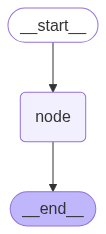

In [ ]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

graph 실행 시 invoke 함수에 **state의 초기값**을 넣어줍니다.

In [ ]:
graph.invoke({"some_text" : "안녕!", "some_number" : 5})

{'some_text': '변경된 텍스트', 'some_number': 15}

### (2) Routing를 추가한 조건부 Graph


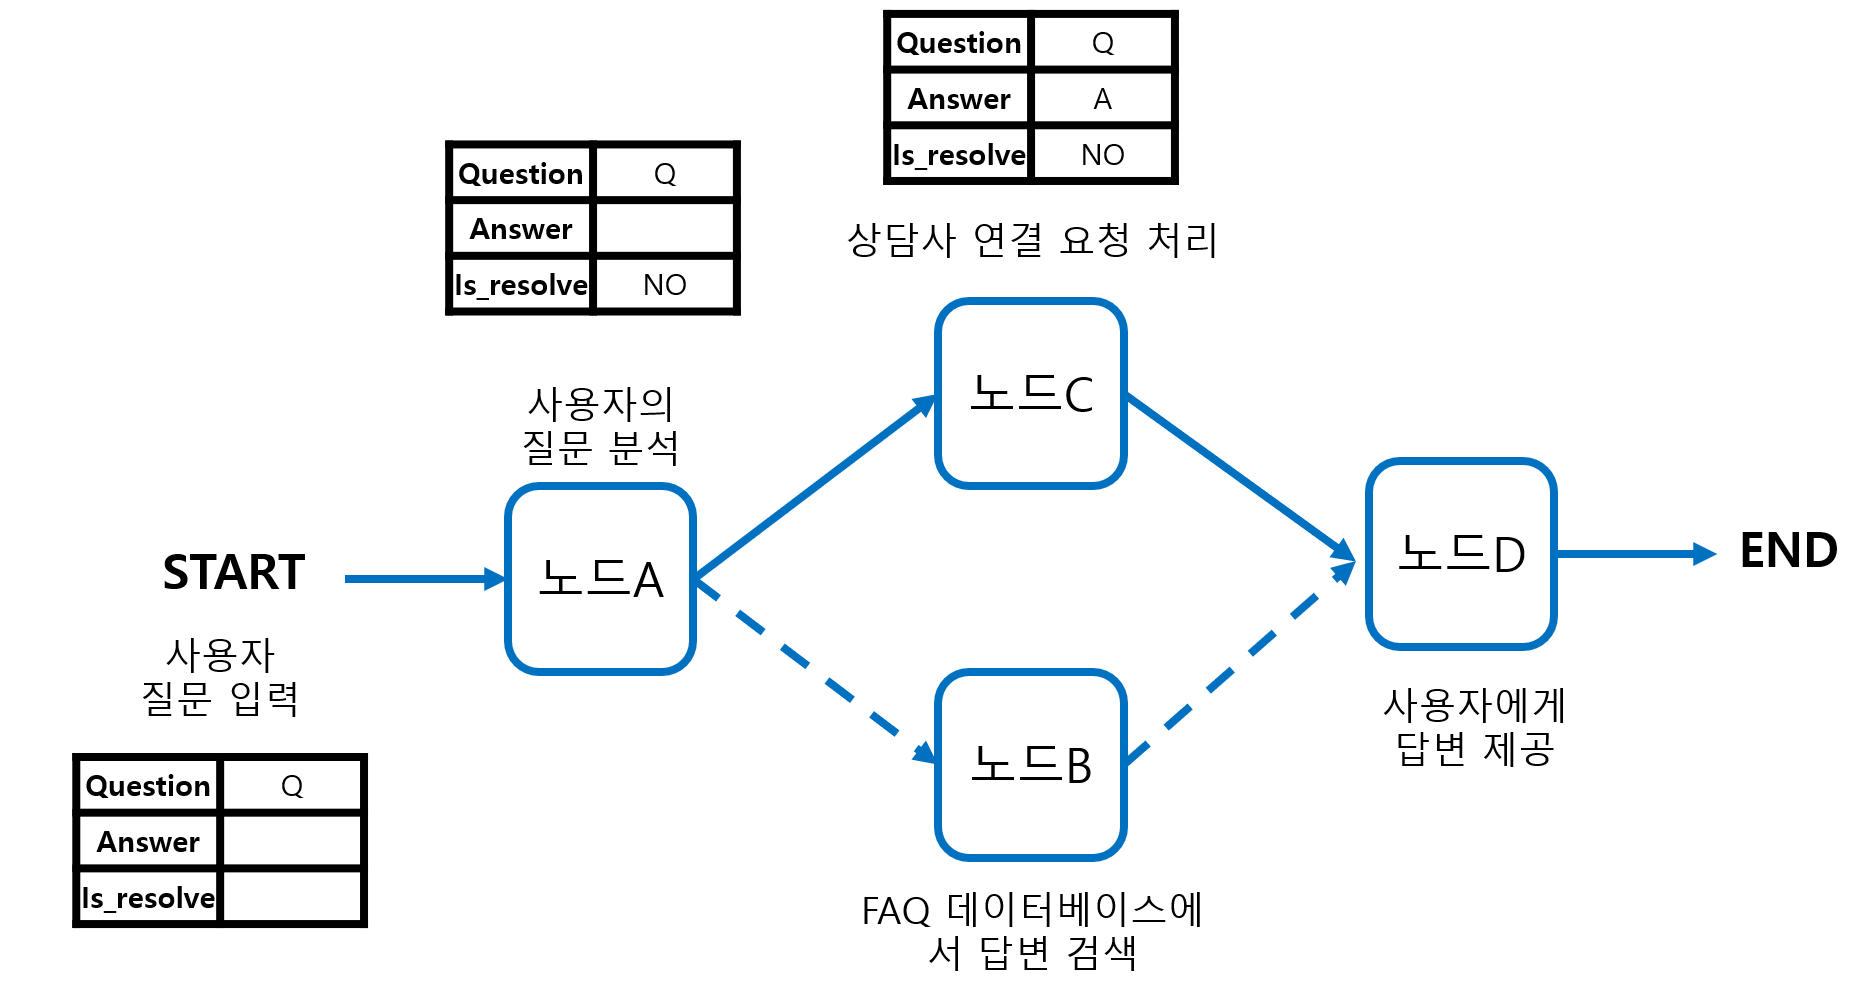





workflow에서 Routing은 매우 중요합니다. *Routing*(라우팅) 은 특정 입력에 따라 서로 다른 경로를 선택하여 실행 흐름을 제어하는 기능입니다. 이를 통해 사용자의 입력이나 특정 조건에 따라 서로 다른 노드를 실행할 수 있습니다.

그래프의 상태 클래스를 정의합니다.

In [ ]:
class State(TypedDict):
    input: str
    decision: str
    output: str

4가지 노드를 정의합니다.

decision_maker => **node_story** or **node_joke** or **node_poem** => END

In [ ]:
# 노드를 정의합니다!
import random

def decision_maker(state: State):
    state['decision'] = random.choice(['story', 'joke', 'poem'])
    return state

def node_story(state: State):
    """Write a story"""

    result = state['input'] + "에 대한 스토리를 작성한다."
    return {"output": result}


def node_joke(state: State):
    """Write a joke"""

    result = state['input'] + "에 대한 농담을 작성한다."
    return {"output": result}


def node_poem(state: State):
    """Write a poem"""

    result = state['input'] + "에 대한 시를 작성한다."
    return {"output": result}

조건부 엣지입니다. 노드와 달리 출력이 state가 아니라는 것을 눈여겨보세요.

어떤 경로로 데이터 흐름을 만들지 결정하기 위한 카테고리를 반환하고 있습니다.

In [ ]:
def route_decision(state: State):
    # Return the node name you want to visit next
    if state["decision"] == "story":
        return "story"
    elif state["decision"] == "joke":
        return "joke"
    elif state["decision"] == "poem":
        return "poem"

이제 노드를 연결해봅시다. decision_maker에서 조건에 따라 story, joke, poem 노드로 이동하도록 할 것입니다.

In [ ]:
# Build workflow
router_builder = StateGraph(State)

In [ ]:
# Add nodes
router_builder.add_node("decision_maker", decision_maker)
router_builder.add_node("node_story", node_story)
router_builder.add_node("node_joke", node_joke)
router_builder.add_node("node_poem", node_poem)


# Add edges to connect nodes
router_builder.add_edge(START, "decision_maker")
router_builder.add_conditional_edges(
    "decision_maker",
    route_decision,
    {   "story": "node_story",
        "joke": "node_joke",
        "poem": "node_poem",} # 조건부 엣지(함수)에서 반환되는 이름과 실제 노드 이름를 매핑합니다.
)
router_builder.add_edge("node_story", END)
router_builder.add_edge("node_joke", END)
router_builder.add_edge("node_poem", END)

# compile the graph
graph = router_builder.compile()

In [ ]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

조건에 따라 다른 노드가 실행되는 것을 확인할 수 있다.

(이번 코드에서의 조건은 확률에 따라 결정되는 decision 상태)

In [ ]:
for i in range(10):
    result = graph.invoke({"input" : "어떤 이야기"})
    print(result)

{'input': '어떤 이야기', 'decision': 'joke', 'output': '어떤 이야기에 대한 농담을 작성한다.'}
{'input': '어떤 이야기', 'decision': 'joke', 'output': '어떤 이야기에 대한 농담을 작성한다.'}
{'input': '어떤 이야기', 'decision': 'poem', 'output': '어떤 이야기에 대한 시를 작성한다.'}
{'input': '어떤 이야기', 'decision': 'poem', 'output': '어떤 이야기에 대한 시를 작성한다.'}
{'input': '어떤 이야기', 'decision': 'story', 'output': '어떤 이야기에 대한 스토리를 작성한다.'}
{'input': '어떤 이야기', 'decision': 'story', 'output': '어떤 이야기에 대한 스토리를 작성한다.'}
{'input': '어떤 이야기', 'decision': 'story', 'output': '어떤 이야기에 대한 스토리를 작성한다.'}
{'input': '어떤 이야기', 'decision': 'joke', 'output': '어떤 이야기에 대한 농담을 작성한다.'}
{'input': '어떤 이야기', 'decision': 'joke', 'output': '어떤 이야기에 대한 농담을 작성한다.'}
{'input': '어떤 이야기', 'decision': 'poem', 'output': '어떤 이야기에 대한 시를 작성한다.'}


### (3) LangGraph RAG

이제 LangGraph로 RAG 시스템을 구현해보겠습니다.

Graph에 질문을 전달하면 이를 처리하여 정답을 반환합니다.

기존의 RAG의 절차를 Graph 형태로 표현하면 됩니다.

In [ ]:
import bs4
from langchain import hub
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import FAISS
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough
from langchain_openai import ChatOpenAI, OpenAIEmbeddings

In [ ]:
urls = ["https://n.news.naver.com/mnews/article/003/0012936785",
        "https://n.news.naver.com/mnews/article/014/0005324853",
        "https://n.news.naver.com/mnews/article/001/0015294812",
        "https://n.news.naver.com/mnews/article/001/0015293069"]

In [ ]:
docs = []
for url in urls:
    loader = WebBaseLoader(
        web_paths=(url,),
        bs_kwargs=dict(
            parse_only=bs4.SoupStrainer(
                "div",
                attrs={"class": ["newsct_article _article_body", "media_end_head_title"]},
            )
        ),
    )
    docs += loader.load()

In [ ]:
print(f"문서의 수: {len(docs)}")

문서의 수: 4


`RecursiveCharacterTextSplitter`는 문서를 지정된 크기의 청크로 나눕니다.

`FAISS` 혹은 `Chroma`와 같은 vectorstore는 이러한 청크를 바탕으로 문서의 벡터 표현을 생성합니다.


In [ ]:
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100)

# chunk_size=1000: 각 청크의 최대 길이는 1000자입니다.
# chunk_overlap=100: 청크 간 겹치는 부분은 100자입니다. 이는 문맥 유지에 도움을 줍니다.

splits = text_splitter.split_documents(docs)
len(splits)
# split_documents(docs)는 docs에 있는 각 문서를 분할하고, 결과를 리스트 형식으로 반환합니다.


# ✅ 최신 OpenAI 임베딩 모델 지정
embedding_model1 = OpenAIEmbeddings(
    model="text-embedding-3-large"
)

# ✅ 벡터스토어 생성
vectorstore = FAISS.from_documents(documents=splits, embedding=embedding_model1)

# ✅ 리트리버 생성. chunk는 5개까지 검색
retriever = vectorstore.as_retriever(search_kwargs={"k": 5})

검색된 컨텍스트를 활용하기 위한 Prompt입니다.

In [ ]:
from langchain_core.prompts import PromptTemplate

template = PromptTemplate.from_template(
    """당신은 질문-답변(Question-Answering)을 수행하는 친절한 AI 어시스턴트입니다. 당신의 임무는 주어진 문맥(context) 에서 주어진 질문(question) 에 답하는 것입니다.
검색된 다음 문맥(context) 을 사용하여 질문(question) 에 답하세요. 만약, 주어진 문맥(context) 에서 답을 찾을 수 없다면, 답을 모른다면 `주어진 정보에서 질문에 대한 정보를 찾을 수 없습니다` 라고 답하세요.
한글로 답변해 주세요. 단, 기술적인 용어나 이름은 번역하지 않고 그대로 사용해 주세요.

#Question:
{question}

#Context:
{context}

#Answer:"""
)

In [ ]:
from langchain_core.documents import Document
from typing_extensions import List, TypedDict

# 상태 정의
class State(TypedDict):
    question: str
    context: str
    answer: str


In [ ]:
# RAG 검색 노드
def retrieve(state: State):
    # 검색기를 통해 질문에 관련된 문서 검색
    docs = retriever.invoke(state["question"])
    # 검색된 문서를 하나의 텍스트로 연결
    context = "\n".join([doc.page_content for doc in docs])
    # return {"context": context}  # 텍스트로 연결된 문맥 반환
    state['context'] = context
    return state

# 생성노드
def generate(state: State):
    # Prompt에 질문과 문맥 전달
    messages = template.invoke({"question": state["question"], "context": state["context"]})
    # LLM 호출 및 응답 생성
    response = llm.invoke(messages).content
    state["answer"] = response  # 생성된 답변 반환
    return state

In [ ]:
from langgraph.graph import START,END,StateGraph

# StateGraph 정의
graph_builder = StateGraph(State)

In [ ]:
# 함수 매핑
graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("generate", generate)

In [ ]:
graph_builder.add_edge(START, "retrieve")
graph_builder.add_edge("retrieve", "generate")
graph_builder.add_edge("generate", END)
graph = graph_builder.compile()

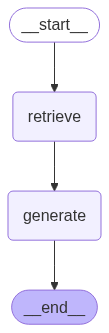

In [ ]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
from langchain_openai import ChatOpenAI

# OpenAI의 ChatOpenAI 모델(GPT-4o)을 사용하여 LLM 초기화
llm = ChatOpenAI(model="gpt-4o-mini")  # 언어 모델을 gpt-4o로 설정

In [ ]:
result = graph.invoke({"question": "한은 총재의 이름은 무엇입니까?"})

print(f'Context: {result["context"]}\n\n')
print(f'Answer: {result["answer"]}')

Context: 한은 '깜짝 인하' 사흘만에…환율 다시 1400원대
높았다. 하지만 FOMC(공개시장위원회) 12월 인하설에 달러가 약세를 보인데 다, 외환당국의 개입 경계도 작용하며 1400원을 넘진 않았다. 이창용 한은 총재는 기자회견에서 "외환보유고는 충분한 수준이며, 국민연금 스와프 금액 확대·재연장을 논의 중"이라고 했다. 이날 환율이 1400원을 넘긴 것은 달러화가 다시 강세로 전환된 영향이 크다. 전날 105선으로 물러났던 달러지수는 106선 초반대로 다시 올라왔다. 일본은행(BOJ)의 12월 인상설에 강세를 보이던 엔화값이 다시 약세를 보였고, 트럼프 미국 대통령 당선자의 중국 100% 관세 경고에 위안화도 약세를 나타냈다. 수출 둔화에 따른 원화값 약세 압력도 더해졌다. 산업통상자원부에 따르면 11월 수출 증가율은 1.4%로 작년 10월 수출 플러스 전환 이후 가장 낮은 수치를 기록했다. 수출 증가율은 1월(18.2%)로 고점을 찍은 후 9월 7.1%로 한 자릿수로 내려온 후 하향세다．
비상 걸린 가계대출...재차 대출 옥죄는 은행권
[서울=뉴시스] 김근수 기자 = 코스피가 전 거래일(2455.91)보다 1.43포인트(0.06%) 내린 2454.48에 마감한 2일 오후 서울 중구 하나은행 본점 딜링룸 전광판에 지수가 표시되고 있다.코스닥 지수는 전 거래일(678.19)보다 2.35포인트(0.35%) 하락한 675.84에 거래를 마쳤으며, 서울 외환시장에서 원·달러 환율은 전 거래일(1394.7원)보다 6.6원 오른 1401.3원에 주간 거래를 마감했다. 2024.12.02. ks@newsis.com[서울=뉴시스]남주현 기자 = 한국은행이 11월 금융통화위원회에서 16여 년만에 '깜짝 인하'를 단행한지 3거래일 만에 환율이 다시 1400원대에 올라섰다. 외환당국의 개입 경계에도 아시아 통화 약세에 따른 달러 강세와 수출 둔화세에 따른 원화 약세 압력이 작용한 것으로 보인다. 29일 서울외환시장에 따르면 이날 오후 종가는 전일 오후 3시30분(13

In [ ]:
result = graph.invoke({"question": "한국은행 부총재는 누구입니까?"})

print(f'Context: {result["context"]}\n\n')
print(f'Answer: {result["answer"]}')

Context: 서울 송파구 롯데월드타워에서 바라본 강남 아파트 단지 모습. 뉴스1[파이낸셜뉴스] 토지거래허가구역 해제로 집값이 급등하면서 은행권이 대출 빗장을 잇따라 걸어잠그고 있다. 올해 초 대출 문턱을 일제히 낮췄지만, 석 달도 안돼 재차 조이기에 나선 상황이다. 대출 수요가 계속 잡히지 않는다면 금리 인상 카드가 나올 수 있다는 전망이다.   23일 금융권에 따르면 앞으로 KB국민·신한·하나은행에서 주택이 1채라도 있는 차주는 수도권에서 집을 매수할 경우 주택담보대출을 받을 수 없다. 우리은행도 오는 28일부터 유주택자에겐 서울 강남·서초·송파·용산구 주택 구입 목적의 신규 주택담보대출을 취급을 중단한다.   그간 하나은행과 우리은행에서는 유주택자라도 제한없이 주택담보대출을 받을 수 있었다. 하지만 금융당국이 집값 과열을 막기 위해 은행권에 자율 관리를 주문하면서 전방위적으로 대출 문턱이 대폭 높아지고 있다.   지난 20일 하나은행은 오는 27일부터 서울 지역에서 유주택자의 주택담보대출 및 조건부 전세자금대출 신규 취급을 중단하는 내용의 대출 규제 방안을 내놨다. 국민은행은 이미 수도권 지역 주택에 대해선 1주택자의 주담대를 제한하고 있고, 신한은행은 기존 주택 처분 조건으로만 1주택자에게 주담대를 내준다. 이제 집을 소유하면서 강남 3구 등에 추가로 주택을 사고자 한다면 4대 은행에선 대출이 가능한 곳이 없다.   올해 초 완화되던 가계대출 규제에 재차 불이 지핀 이유는 토지거래허가구역 번복 등으로 집값 상승폭이 확대됐기 때문이다. 토지거래허가구역을 해제한 이후 강남 3구를 중심으로 집값이 크게 오르고 인근 지역으로 매수가 확산되면서 주택담보대출 잔액도 증가했다. 5대 은행의 주담대 잔액은 지난달 말 기준 583조3607억원으로, 전월 대비 3조3836억원 급증했다.   당국이 가계대출 관리에 힘을 주면서 금리 인하기에 들어섰음에도 외려 금리가 오르는 상황이다. 24일부터 수도권의 신규 분양 주택을 담보로 디딤돌 대출을 신청하는 경우 0.1%p 의 

### (4) RAG로 찾지 못한 내용을 웹에서 검색

자체 데이터베이스를 활용하는 RAG 내에 응답을 위한 정보가 없을 수도 있습니다.

우리는 1차적으로 RAG에서 적절한 컨텍스트를 찾지 못 했다면, 우리가 알고 있는 가장 거대한 데이터베이스를 활용해볼 수 있습니다.

바로 인터넷에서 컨텍스트를 찾는 것입니다.

**Tavily API 사용을 위한 API KEY 등록**

Tavily는 LLM과 web 검색을 연동하기 위한 API입니다. 역시 API를 사용하기 위해 Key값을 받아와야 합니다.

[Tavily.com](https://app.tavily.com/)에 접속해 가입하고, API key를 생성합시다.

In [ ]:
os.environ["TAVILY_API_KEY"] = "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"

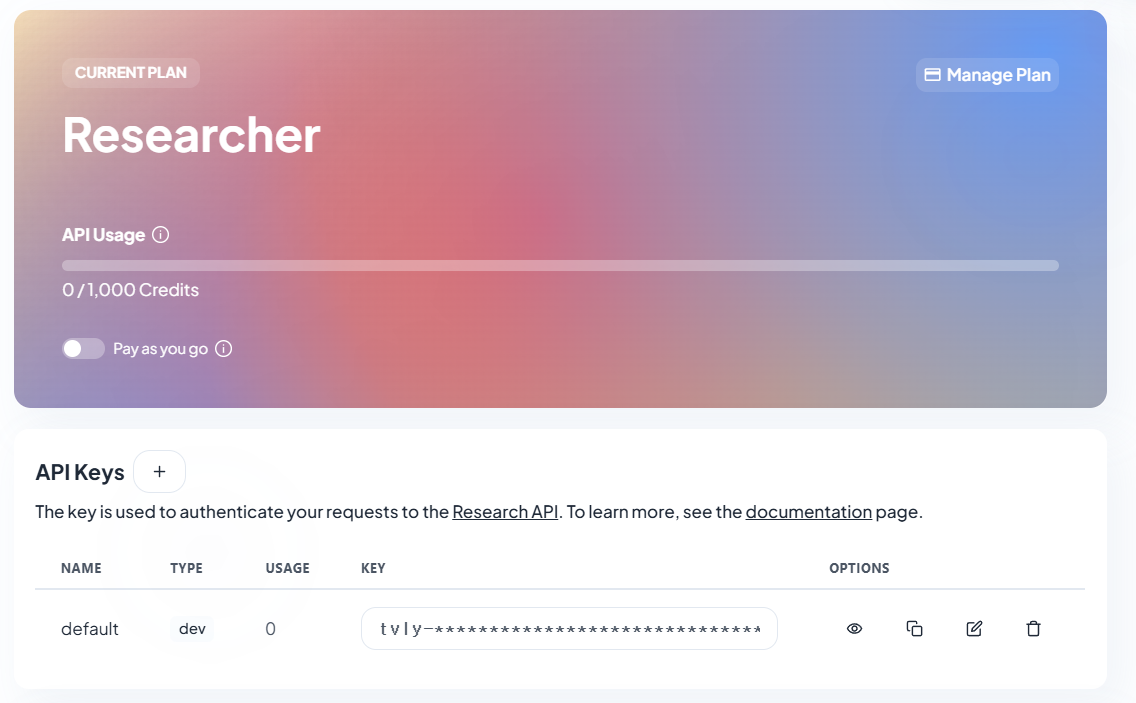

In [ ]:
from langchain_tavily import TavilySearch

tavily_search = TavilySearch(
    max_results=3,
    topic="general",
    include_raw_content=True)

search_docs = tavily_search.invoke("2025년도 대한민국 공휴일")

In [ ]:
search_docs

{'query': '2025년도 대한민국 공휴일',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://vclock.kr/holidays/',
   'title': '대한민국의 공휴일 - 2025 - 2026',
   'content': "대한민국의 공휴일 - 2025 - 2026 대한민국의 공휴일 - 2025 - 2026 *   공휴일 공휴일 양력설2026년 1월 1일 126일 설날2026년 2월 16일 172일 3·1절2026년 3월 1일 185일 어린이날2026년 5월 5일 250일 석가탄신일2026년 5월 24일 269일 현충일2026년 6월 6일 282일 광복절2026년 8월 15일 352일 추석2025년 10월 6일 39일 개천절2025년 10월 3일 36일 한글날2025년 10월 9일 42일 예수탄신일2025년 12월 25일 119일 대한민국의 공휴일 공휴일 은 국가나 공공기관 등에서 공식적으로 지정한 휴일을 일컫는 말. 대한민국에는 국민 전체를 기속(羈束)하는 공휴일에 관한 법률이 없으며, 대통령령인 '관공서의 공휴일에 관한 규정'에서 국가기관이나 지방 정부 등의 공휴일을 정하고 있다. 따라서, 민간기업이나 민간단체는 노사간의 합의(주로 '단체협약'이나 '취업규칙')를 통해 스스로 휴일을 정할 수 있기 때문에 관공서의 공휴일에 쉬어야 할 법적 의무는 없으나, 관행상 '관공서의 공휴일에 관한 규정'을 준용하여 휴일로 써왔다.",
   'score': 0.9556888,
   'raw_content': "대한민국의 공휴일 - 2025 - 2026\n\n===============\n\n대한민국의 공휴일 - 2025 - 2026\n\n[](javascript:;)[](https://vclock.kr/)\n\n[](javascript:;)[](javascript:;)\n\n*   [](javascript:;)\n\n*   [공휴일](https

Tavily는 LLM을 위한 검색 서비스를 제공하는 api입니다. LangChain과 쉽게 연결할 수 있는 인터페이스를 제공합니다.

앞서서 구축한 RAG graph에서 generate 노드에 조건부 엣지를 추가해보겠습니다.

조건은 모델이 데이터베이스에서 정보를 찾았는 지 여부입니다.

- 정보를 찾았다면 generate 노드의 출력을 END 노드로 연결합니다.
- 정보를 찾지 못 했다면, 외부 api를 활용하는 agent 기능을 활용해 검색하여 context를 찾습니다.

정보를 찾을 때까지 loop를 돌며 조건을 확인합니다.




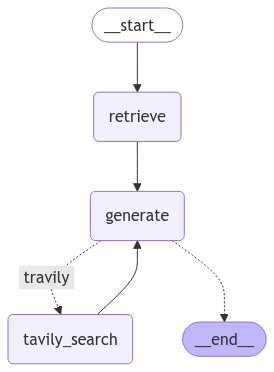

In [ ]:
from typing_extensions import TypedDict

# 상태 정의
class State(TypedDict):
    question: str
    context: str
    answer: str
    loop_count : int

# Tavily 검색 노드
def tavily_search(state: State):
    """Tavily 검색을 사용해 추가 문서를 검색합니다."""
    tavily_search = TavilySearch(max_results=3, topic="general", include_raw_content=True)
    search_docs = tavily_search.invoke(state["question"])

    # Tavily 검색 결과를 텍스트로 직렬화
    context = "\n\n".join(
        f"URL: {doc['url']}\nContent: {doc['content']}" for doc in search_docs
    )
    state['context'] = context
    return state

# RAG 검색 노드
def retrieve(state: State):
    # 검색기를 통해 질문에 관련된 문서 검색
    docs = retriever.invoke(state["question"])
    # 검색된 문서를 하나의 텍스트로 연결
    context = "\n".join([doc.page_content for doc in docs])
    # return {"context": context}  # 텍스트로 연결된 문맥 반환
    state['context'] = context
    return state

# 생성노드
def generate(state: State):
    # Prompt에 질문과 문맥 전달
    messages = template.invoke({"question": state["question"], "context": state["context"]})
    # LLM 호출 및 응답 생성
    response = llm.invoke(messages).content
    state["answer"] = response  # 생성된 답변 반환
    return state

In [ ]:
from langgraph.graph import StateGraph, START, END

# LangGraph 빌더 초기화
graph_builder = StateGraph(State)

# 노드 추가
graph_builder.add_node("retrieve", retrieve)  # 기본 검색 노드
graph_builder.add_node("generate", generate)  # 답변 생성 노드
graph_builder.add_node("tavily_search", tavily_search)  # Tavily 검색 노드

In [ ]:
def conditional_edge_check_context(
    state: State,
):
    # 루프 회수를 기록할 변수를 초기화 (state에 저장)
    if "loop_count" not in state:
        state["loop_count"] = 0

    # 루프 회수를 증가
    state["loop_count"] += 1

    # 루프 종료 조건: 특정 회수를 초과하면 END로 반환
    if state["loop_count"] > 3:  # 최대 루프 회수를 3으로 설정
        return END


    # TODO: context에 질문에 대한 정보가 있는 지 확인하고, 없다면 웹검색을 시도합니다.
    if state["answer"]:
        return "travily"
    else:
        return END



    pass


# 엣지 연결
graph_builder.add_edge(START, "retrieve")  # 시작 → 기본 검색
graph_builder.add_edge("retrieve", "generate")  # 기본 검색 → 답변 생성
# `tools_condition` 함수는 챗봇이 도구 사용을 요청하면 "tools"를 반환하고, 직접 응답이 가능한 경우 "END"를 반환
graph_builder.add_conditional_edges(
    source="generate",
    path= conditional_edge_check_context ,
    # route_tools 의 반환값이 "tools" 인 경우 "tools" 노드로, 그렇지 않으면 END 노드로 라우팅
    path_map={"travily": "tavily_search", END: END}
)

graph_builder.add_edge("tavily_search", "generate")  # Tavily 검색 → 다시 답변 생성
=
# 그래프 컴파일
graph = graph_builder.compile()

SyntaxError: invalid syntax (ipython-input-2245466957.py, line 39)

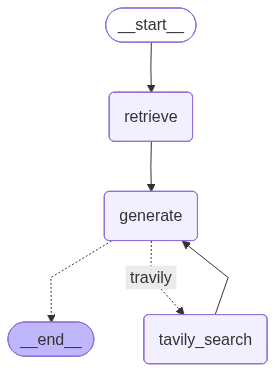

In [ ]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
result = graph.invoke({"question": "한은 총재의 이름은 무엇입니까?"})

print(f'Context: {result["context"]}\n\n')
print(f'Answer: {result["answer"]}')

KeyError: None

In [ ]:
result = graph.invoke({"question": "한국은행 부총재 이름은?"})

print(f'Context: {result["context"]}\n\n')
print(f'Answer: {result["answer"]}')

KeyError: None